# Farmer Support Application — Final ML Engine
**Semester project | Model development, validation and live demonstration**

## 1. Research problem and technical solution
Farmers need accessible crop advice, a way to assess buyer offers and information about alternative markets. The mobile application uses a price engine (linear quantile regression, offer checks and market ranking). The crop advisory prototype uses TF-IDF retrieval to find related agricultural Q&A, not to establish a disease diagnosis.

## How to run
Extract the project ZIP, open `Model_Final.ipynb` in the project folder and run from top to bottom. The supplied `outputs` folder contains the price data and app inference code. Install the packages in `requirements.txt` if necessary. Both engines were executed against the supplied data. The included `outputs/crop_qa_clean.csv` enables offline advisory training. The optional raw-data download pipeline is disabled by default. No fabricated advisory data or metrics are used.


Install dependencies if needed using `pip install -r requirements.txt`. For online advisory acquisition additionally install `datasets huggingface_hub requests beautifulsoup4 lxml`.

# 2. Price engine — training, testing and validation
The supplied historical price data is used to fit, calibrate and evaluate the models before exporting the app engine.

## 1. Setup and data

In [1]:
import warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import QuantileRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
def find_dir(candidates, filename):
    for c in candidates:
        if (Path(c) / filename).exists():
            return Path(c)
    return None
# Expected layout next to this notebook:  outputs/model_dataset.csv, outputs/market_distances.csv, outputs/markets_coordinates.csv, outputs/price_ai.py
OUT_DIR = find_dir(["outputs", ".", "/content/outputs", "/content", "/mnt/user-data/outputs"], "model_dataset.csv")
if OUT_DIR is None:
    import os
    raise FileNotFoundError("model_dataset.csv not found.\n"
                            f"This notebook is running in the folder: {os.getcwd()}\n"
                            "Put a folder called 'outputs' (with model_dataset.csv, market_distances.csv, markets_coordinates.csv and price_ai.py) "
                            "inside that folder, then run this cell again.") from None

d = pd.read_csv(OUT_DIR / "model_dataset.csv", parse_dates=["date"])
pairs = pd.read_csv(OUT_DIR / "market_distances.csv")
loc = pd.read_csv(OUT_DIR / "markets_coordinates.csv")
u = d[d["usable"]].copy()                       # rows with a wholesale price (target) and a reference price
print(f"{len(d):,} rows in model_dataset.csv, {len(u):,} usable for modelling ({u.market.nunique()} markets)")
u.groupby(["crop", "split"]).agg(rows=("date", "size"), first=("date", "min"), last=("date", "max")).assign(
    first=lambda x: x["first"].dt.date, last=lambda x: x["last"].dt.date).unstack("split")

26,774 rows in model_dataset.csv, 22,854 usable for modelling (215 markets)


rows             first                    last            
split                 test train        test       train        test       train
crop                                                                            
Cabbages               449  1824  2026-07-07  2024-10-06  2026-10-28  2026-07-06
Carrots               1216  5146  2025-10-17  2013-01-25  2026-10-27  2025-10-16
Red Irish potatoes     787  3729  2024-01-23  2013-01-08  2026-10-27  2024-01-22
Tomatoes              1447  5887  2025-12-01  2021-12-14  2026-10-28  2025-11-30
White Irish potatoes   488  1881  2026-05-24  2024-07-02  2026-10-27  2026-05-23

**The split is by time** (built in the data notebook): the latest 20% of dates for each crop is the *test set* and is not touched while the model is built. The test periods differ in length (about 4 months for cabbages, 12 months for tomatoes and carrots), so a result for one crop is not directly comparable to another's.

**Target:** the wholesale price in KES per kg. **Important limit:** KAMIS does not record farm-gate prices, so the model predicts the *wholesale* price. How a farm-gate offer is judged against it is a separate, rule-based step (section 5).

### 1.1 Features

In [2]:
def make_X(g):
    """Everything here was known BEFORE the day being predicted (built from earlier dates only)."""
    X = pd.DataFrame(index=g.index)
    X["l_ref"] = np.log(g.reference_price)                                     # last reported price in this market
    X["l_mkt"] = np.log(g.market_median_before.fillna(g.reference_price))      # this market's usual level
    X["l_cty"] = np.log(g.county_median_before.fillna(g.reference_price))      # the county's usual level
    X["stale"] = np.log1p(g.days_since_last.fillna(60).clip(upper=60))         # how old the last price is
    X["ms"], X["mc"] = g.month_sin, g.month_cos                                # season
    X["l_ret"] = np.log(g.retail_kes_kg)                                       # retail price the same day (NaN when not reported)
    return X

FEATS_A = ["l_ref", "l_mkt", "l_cty", "stale", "ms", "mc"]     # variant A: price history only
FEATS_B = FEATS_A + ["l_ret"]                                  # variant B: history plus the same-day retail price
make_X(u).describe().round(2).loc[["count", "mean", "min", "max"]]

,l_ref,l_mkt,l_cty,stale,ms,mc,l_ret
count,22854.00,22854.00,22854.00,22854.00,22854.0,22854.00,19075.00
mean,3.73,3.67,3.66,1.85,-0.0,-0.05,4.16
min,1.79,1.79,1.98,0.69,-1.0,-1.00,2.30
max,5.30,4.87,4.79,4.11,1.0,1.00,7.09


**Why logs.** Prices are modelled on the log scale, so errors are *proportional* (a KES 5 miss matters more on a KES 20 cabbage than on a KES 80 tomato) and the predicted range is always positive and widens naturally when prices are high.

**Two variants, because the information differs by use.**
- **A, history only:** needs nothing but earlier prices. This is what the market finder can use to look ahead, and the fallback for the offer checker.
- **B, with retail:** adds the retail price reported in the same market on the same day. When it is available it is the more accurate choice (the earlier analysis showed wholesale is a steady 70% to 78% of retail). Variant B can only be used for rows where a retail price exists (about 83% of rows).

Same-day prices of *other* markets were also tried and added almost nothing, so they are left out.

## 2. Baselines (the scores the model has to beat)

In [3]:
def mape(y, p): return float(np.mean(np.abs(y - p) / y) * 100)
def mae(y, p):  return float(np.mean(np.abs(y - p)))
def within(y, p, tol=0.10): return float(np.mean(np.abs(y - p) / y <= tol) * 100)

te = u[u.split == "test"]
base = []
for crop, g in te.groupby("crop"):
    y = g.wholesale_kes_kg.values
    row = {"crop": crop, "test rows": len(g)}
    for name, col in [("last price", "reference_price"), ("market median", "market_median_before"), ("county median", "county_median_before")]:
        p = g[col].fillna(g.reference_price).values
        row[f"{name}: MAPE %"] = round(mape(y, p), 1)
    row["last price: within 10% (% of rows)"] = round(within(y, g.reference_price.values), 1)
    row["last price: MAE KES/kg"] = round(mae(y, g.reference_price.values), 2)
    base.append(row)
baselines = pd.DataFrame(base).set_index("crop")
baselines

,test rows,last price: MAPE %,market median: MAPE %,county median: MAPE %,last price: within 10% (% of rows),last price: MAE KES/kg
crop,,,,,,
Cabbages,449,13.9,17.4,26.9,55.5,3.93
Carrots,1216,13.8,19.3,24.1,51.7,6.85
Red Irish potatoes,787,16.1,24.6,29.2,52.6,8.64
Tomatoes,1447,16.6,29.0,43.3,55.8,8.46
White Irish potatoes,488,11.5,16.2,20.1,62.7,6.88


**Reading it.** "Same as the last price in this market" is already a strong baseline (MAPE about 12% to 17%), far better than a long-run market or county median. That is expected from the data analysis: prices are rounded, and in 44% of cases the price is *exactly* the last one. The model has to be judged against *last price*, not against nothing.

## 3. The model: linear quantile regression with calibrated ranges

**Linear quantile regression** fits three straight-line models on the log price: the 10th percentile (low), the 50th (expected) and the 90th (high). They give an expected price and a range, which is what the offer checker needs.

**Calibration (conformal adjustment).** Raw quantile models are often a little too narrow or too wide on new data. For each crop, the training data is split by time: the first 80% of training dates fit the model and the **last 20% of training dates** are used only to measure how far real prices fell outside the range. The range is widened by that amount (never narrowed) so that about 80% of prices should fall inside. The test set is not used in any of this.

**Per crop.** Each of the five crops has its own model, because their prices, seasons and volatility differ.

In [4]:
QS = (0.1, 0.5, 0.9)
ALPHA = 0.2          # a 10th to 90th percentile range should contain 80% of prices

def fit_variant(tr, feats):
    tr = tr.sort_values("date")
    cut = tr.date.quantile(0.8)
    core, cal = tr[tr.date <= cut], tr[tr.date > cut]
    y_core = np.log(core.wholesale_kes_kg)
    models = {q: QuantileRegressor(quantile=q, alpha=0, solver="highs").fit(make_X(core)[feats], y_core) for q in QS}
    y_cal = np.log(cal.wholesale_kes_kg); Xc = make_X(cal)[feats]
    s = np.maximum(models[0.1].predict(Xc) - y_cal, y_cal - models[0.9].predict(Xc))      # how far outside the range
    n = len(s)
    Q = max(0.0, float(np.quantile(s, min(1.0, np.ceil((n + 1) * (1 - ALPHA)) / n))))      # widen only
    return models, Q

def predict_range(models, Q, g, feats):
    X = make_X(g)[feats]
    med = np.exp(models[0.5].predict(X))
    lo = np.minimum(np.exp(models[0.1].predict(X) - Q), med)
    hi = np.maximum(np.exp(models[0.9].predict(X) + Q), med)
    return lo, med, hi

fitted, parts = {}, []
for crop, g in u.groupby("crop"):
    tr, te_ = g[g.split == "train"], g[g.split == "test"].copy()
    mA, QA = fit_variant(tr, FEATS_A)
    mB, QB = fit_variant(tr.dropna(subset=["retail_kes_kg"]), FEATS_B)
    fitted[crop] = {"A": (mA, QA), "B": (mB, QB)}
    te_["loA"], te_["medA"], te_["hiA"] = predict_range(mA, QA, te_, FEATS_A)
    r = te_.retail_kes_kg.notna()
    for c in ("loB", "medB", "hiB"): te_[c] = np.nan
    te_.loc[r, ["loB", "medB", "hiB"]] = np.column_stack(predict_range(mB, QB, te_[r], FEATS_B))
    # deployed rule: variant B when a retail price exists, otherwise variant A
    te_["variant"] = np.where(r, "B", "A")
    te_["lo"], te_["med"], te_["hi"] = te_.loB.fillna(te_.loA), te_.medB.fillna(te_.medA), te_.hiB.fillna(te_.hiA)
    parts.append(te_)
pred = pd.concat(parts)
pred["y"] = pred.wholesale_kes_kg
print("calibration widening (log scale; 0 = none), variant A / variant B:")
print({c: (round(v["A"][1], 3), round(v["B"][1], 3)) for c, v in fitted.items()})
print("test rows predicted:", len(pred), "| using retail (variant B):", int((pred.variant == "B").sum()))

calibration widening (log scale; 0 = none), variant A / variant B:
{'Cabbages': (0.0, 0.017), 'Carrots': (0.023, 0.0), 'Red Irish potatoes': (0.131, 0.023), 'Tomatoes': (0.0, 0.0), 'White Irish potatoes': (0.019, 0.005)}
test rows predicted: 4387 | using retail (variant B): 4229


## 4. Results on the test set

In [5]:
def summarise(g, med_col="med", lo_col="lo", hi_col="hi"):
    y = g.y.values
    return pd.Series({"test rows": len(g),
                      "last-price MAPE %": mape(y, g.reference_price.values), "model MAPE %": mape(y, g[med_col].values),
                      "last-price MAE": mae(y, g.reference_price.values), "model MAE": mae(y, g[med_col].values),
                      "within 10%: last price": within(y, g.reference_price.values), "within 10%: model": within(y, g[med_col].values),
                      "80% range holds %": float(np.mean((y >= g[lo_col]) & (y <= g[hi_col])) * 100),
                      "range width (high/low)": float(np.mean(g[hi_col] / g[lo_col]))})

res = pred.groupby("crop").apply(summarise)
overall = summarise(pred).rename("ALL CROPS").to_frame().T
display(pd.concat([res, overall]).round(2))

,test rows,last-price MAPE %,model MAPE %,last-price MAE,model MAE,within 10%: last price,within 10%: model,80% range holds %,range width (high/low)
Cabbages,449.0,13.92,14.30,3.93,3.82,55.46,50.11,80.85,1.62
Carrots,1216.0,13.78,13.45,6.85,6.58,51.73,54.61,88.82,1.62
Red Irish potatoes,787.0,16.07,13.83,8.64,7.68,52.60,52.48,89.07,1.89
Tomatoes,1447.0,16.57,15.55,8.46,7.74,55.77,56.88,81.06,1.56
White Irish potatoes,488.0,11.55,10.91,6.88,6.62,62.70,63.11,82.79,1.49
ALL CROPS,4387.0,14.87,14.02,7.41,6.88,54.82,55.46,84.82,1.63


In [6]:
# Variant A (history only) on all test rows, and variant B on the rows that have a retail price
pa = pred.copy()
resA = pa.groupby("crop").apply(lambda g: summarise(g, "medA", "loA", "hiA"))
pb = pred[pred.variant == "B"]
resB = pb.groupby("crop").apply(lambda g: summarise(g, "medB", "loB", "hiB"))
comp = pd.DataFrame({"last-price MAPE % (retail rows)": resB["last-price MAPE %"], "A: history only, MAPE %": pb.groupby("crop").apply(lambda g: mape(g.y.values, g.medA.values)),
                     "B: with retail, MAPE %": resB["model MAPE %"], "A: range holds %": pb.groupby("crop").apply(lambda g: np.mean((g.y >= g.loA) & (g.y <= g.hiA)) * 100),
                     "B: range holds %": resB["80% range holds %"], "rows": resB["test rows"]}).round(1)
comp

,last-price MAPE % (retail rows),"A: history only, MAPE %","B: with retail, MAPE %",A: range holds %,B: range holds %,rows
crop,,,,,,
Cabbages,13.8,13.8,14.1,81.3,81.5,428.0
Carrots,13.9,13.9,13.6,79.2,88.8,1183.0
Red Irish potatoes,15.7,15.7,13.4,90.0,89.5,771.0
Tomatoes,16.0,16.0,14.9,83.0,81.6,1386.0
White Irish potatoes,11.6,11.6,10.9,84.2,82.4,461.0


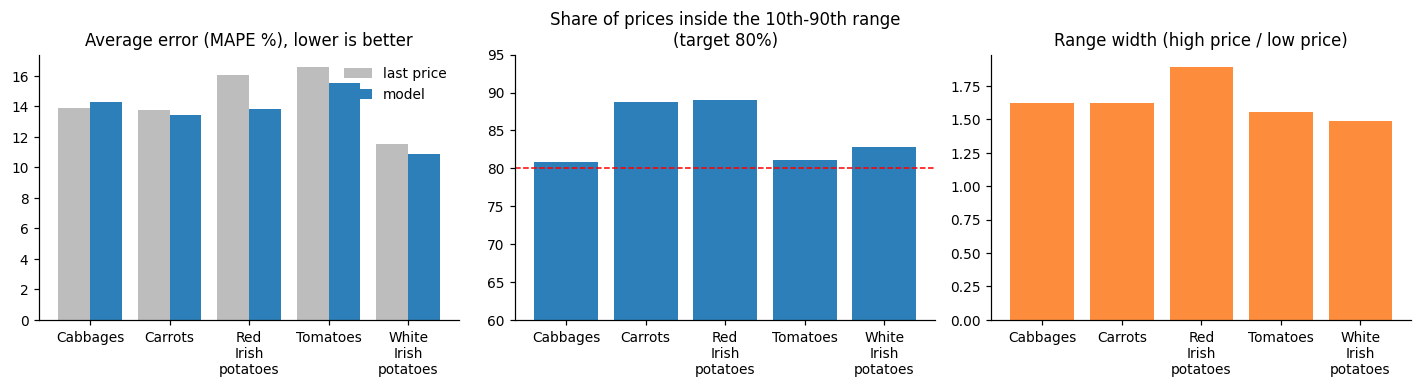

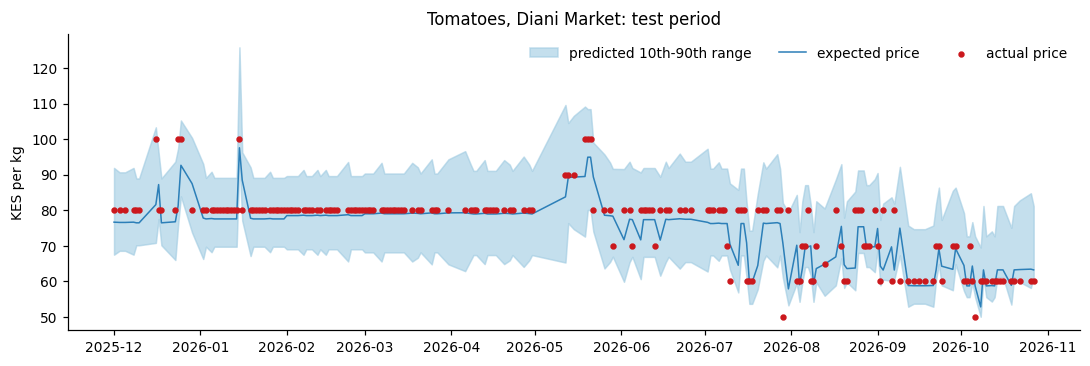

Diani Market | actual price inside the range: 92 % of 196 readings


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
crops = list(res.index); xs = np.arange(len(crops)); lab = [c.replace(" ", "\n") for c in crops]
axes[0].bar(xs - 0.2, res["last-price MAPE %"], 0.4, label="last price", color="#bdbdbd"); axes[0].bar(xs + 0.2, res["model MAPE %"], 0.4, label="model", color="#2c7fb8")
axes[0].set_xticks(xs); axes[0].set_xticklabels(lab); axes[0].set_title("Average error (MAPE %), lower is better"); axes[0].legend(frameon=False)
axes[1].bar(xs, res["80% range holds %"], color="#2c7fb8"); axes[1].axhline(80, ls="--", color="red", lw=1)
axes[1].set_xticks(xs); axes[1].set_xticklabels(lab); axes[1].set_title("Share of prices inside the 10th-90th range\n(target 80%)"); axes[1].set_ylim(60, 95)
axes[2].bar(xs, res["range width (high/low)"], color="#fd8d3c"); axes[2].set_xticks(xs); axes[2].set_xticklabels(lab); axes[2].set_title("Range width (high price / low price)")
plt.tight_layout(); plt.show()

# One market over time: actual wholesale price against the predicted range (a market with many test readings)
mk = pred[pred.crop == "Tomatoes"].groupby("market").size().sort_values(ascending=False).index[0]
g = pred[(pred.crop == "Tomatoes") & (pred.market == mk)].sort_values("date")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.fill_between(g.date, g.lo, g.hi, color="#9ecae1", alpha=0.6, label="predicted 10th-90th range")
ax.plot(g.date, g.med, color="#2c7fb8", lw=1, label="expected price"); ax.scatter(g.date, g.y, s=10, color="#cb181d", zorder=3, label="actual price")
ax.set_title(f"Tomatoes, {mk}: test period"); ax.set_ylabel("KES per kg"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()
print(mk, "| actual price inside the range:", round(float(((g.y >= g.lo) & (g.y <= g.hi)).mean() * 100)), "% of", len(g), "readings")

**Reading the results (test set, 4,387 market-days).**

- **A small but real improvement over "same as the last price".** The average error is 14.0% against 14.9% for the baseline (about KES 6.9 against 7.4 per kg). It is better for red potatoes (16.1% to 13.8%), tomatoes (16.6% to 15.6%), white potatoes (11.5% to 10.9%) and carrots (13.8% to 13.5%), and slightly *worse* for cabbages (13.9% to 14.3%), whose test period is only four months.
- **The gain comes from the retail price.** With price history only (variant A) the expected price is simply the last price, so the error is identical to the baseline for every crop. With the same-day retail price (variant B) the error falls by 0.7 to 2.3 points for red potatoes (15.7% to 13.4%), tomatoes (16.0% to 14.9%), white potatoes (11.6% to 10.9%) and, barely, carrots (13.9% to 13.6%), but not for cabbages. So the history-only model's real value is its **range**, not its point estimate.
- **The range is reliable.** 85% of actual prices fall between the predicted low and high (the target was 80%), from 81% for cabbages and tomatoes to 89% for carrots and red potatoes. The high price is typically 1.5 to 1.9 times the low price, so the range is wide, and a little wider than necessary for carrots and red potatoes.
- **What "accuracy" means here.** The expected price is within 10% of the actual price in 55% of cases (the same as the baseline), and the average error is 14%, which is a percentage error, not a classification accuracy. A 95% accuracy claim is not supported by this evaluation.

### 4.1 Where does it work and where does it fail?

In [8]:
def seg(g):
    return pd.Series({"rows": len(g), "last-price MAPE %": mape(g.y.values, g.reference_price.values), "model MAPE %": mape(g.y.values, g.med.values),
                      "80% range holds %": float(np.mean((g.y >= g.lo) & (g.y <= g.hi)) * 100)})
pred["age"] = pd.cut(pred.days_since_last, [-1, 7, 30, 90, 10**6], labels=["0-7 days", "8-30 days", "31-90 days", "over 90 days"])
print("By how old the last price is:"); display(pred.groupby("age").apply(seg).round(1))
print("By where the reference price came from:"); display(pred.groupby("reference_source").apply(seg).round(1))
print("By location quality of the market:"); display(pred.groupby("location_quality").apply(seg).round(1))

By how old the last price is:


,rows,last-price MAPE %,model MAPE %,80% range holds %
age,,,,
0-7 days,3215.0,12.7,12.9,84.0
8-30 days,842.0,17.0,15.0,88.0
31-90 days,170.0,24.8,18.2,88.8
over 90 days,142.0,36.2,26.6,81.7


By where the reference price came from:


,rows,last-price MAPE %,model MAPE %,80% range holds %
reference_source,,,,
county_median,18.0,45.0,32.7,66.7
last_market_price,4369.0,14.7,13.9,84.9


By location quality of the market:


,rows,last-price MAPE %,model MAPE %,80% range holds %
location_quality,,,,
Approximate,1087.0,17.3,15.1,85.9
Matched by name,1909.0,15.3,15.7,84.5
Town centre,1391.0,12.4,10.8,84.4


**Where it fails.**

- **Old prices.** Most test rows (3,215) have a last price under a week old, with an error of 12.9%. The error climbs as the last price ages: 15.0% at 8 to 30 days, 18.2% at 31 to 90 days and 26.6% beyond 90 days (the "last price" baseline reaches 36% there). 312 rows (7%) are older than 30 days. The app should always show the age of the last price and warn when it is old.
- **No recent price at all.** Only 18 test rows had to fall back to the county median, and they are poor (33% error, with the range holding only 67% of the time). A market with no history should get a clearly flagged, wider answer.
- **Location quality does not matter for the price model.** The error depends on the kind of market, not on whether its coordinates are approximate (15.1% approximate, 15.7% matched by name, 10.8% town centre). Location quality matters only for the market finder's distances.

## 5. Offer checker

**How a verdict is made.** The model gives the expected *wholesale* price W for the crop and market. A buyer paying a farmer at the farm gate pays less than W, so the offer is compared with a **farmer's-share band** of W: `[share_low × W, share_high × W]`. Below the band the offer is *low*, inside it *fair*, above it *good*.

**The band is an assumption, not something the data can supply** (KAMIS has no farm-gate prices). The default is 35% to 52%, the farm-gate share of the wholesale price reported for potatoes in Nakuru and Eldoret in 2009 to 2010 in the study's own literature review (Laibuni and Omiti, 2014). It is old, from one crop and two markets, and other evidence in the review suggests brokers in Kirinyaga paid more than that share for tomatoes, so the group must set its own benchmark before the app goes anywhere near a farmer. The sections below show what the *model* contributes and how sensitive the verdict is to the band.

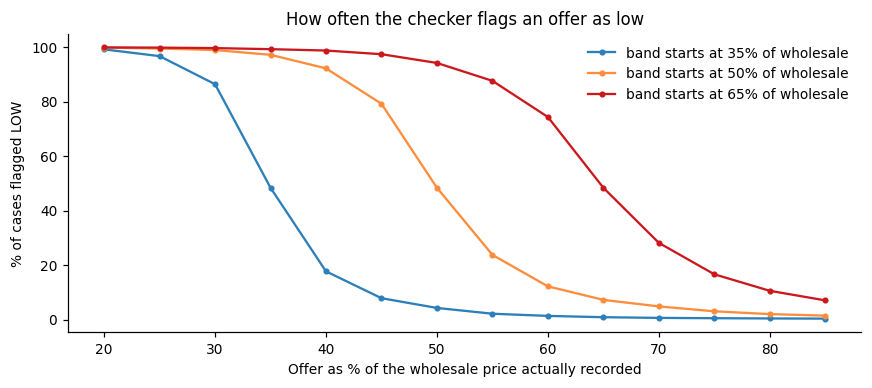

,"flagged low, band starts 35%","flagged low, band starts 50%","flagged low, band starts 65%"
offer % of wholesale,,,
25,97.0,99.0,100.0
30,86.0,99.0,100.0
35,48.0,97.0,99.0
40,18.0,92.0,99.0
45,8.0,79.0,97.0
50,4.0,48.0,94.0
55,2.0,24.0,88.0
60,1.0,12.0,74.0
70,1.0,5.0,28.0


In [9]:
# How well does the model-based check catch a low offer?
# Simulation: suppose a farmer is offered a share r of the wholesale price actually recorded that day (y).
# The checker (which does not know y) flags the offer as LOW when r*y is below share_low times its expected wholesale price.
shares = np.round(np.arange(0.20, 0.86, 0.05), 2)
curves = {}
for sl in (0.35, 0.50, 0.65):
    curves[sl] = [float(np.mean(r * pred.y < sl * pred.med) * 100) for r in shares]
fig, ax = plt.subplots(figsize=(8, 3.6))
for sl, c in zip(curves, ("#2c7fb8", "#fd8d3c", "#cb181d")):
    ax.plot(shares * 100, curves[sl], marker="o", ms=3, label=f"band starts at {int(sl*100)}% of wholesale", color=c)
ax.set_xlabel("Offer as % of the wholesale price actually recorded"); ax.set_ylabel("% of cases flagged LOW"); ax.legend(frameon=False)
ax.set_title("How often the checker flags an offer as low")
plt.tight_layout(); plt.show()
tab = pd.DataFrame(curves, index=(shares * 100).astype(int)); tab.index.name = "offer % of wholesale"; tab.columns = [f"flagged low, band starts {int(c*100)}%" for c in tab.columns]
tab.loc[[25, 30, 35, 40, 45, 50, 55, 60, 70]].round(0)

**Reading it.** With a band that starts at 35% of the wholesale price, an offer at 25% of wholesale is flagged as low 97% of the time, at 30% it is flagged 86% of the time, at 35% (right on the edge) 48%, at 40% 18%, and at 50% only 4%. The verdict flips from "low" to "not low" over roughly 10 percentage points of share around the edge. That blur is the prices' own noise (about 14% error) showing through: the checker is dependable for clearly low or clearly good offers and unreliable for offers near the line. It should show the wholesale range next to the verdict (the module does).

The three curves also show that **the band matters more than the model**: the same offer of 40% of wholesale is flagged 18% of the time with a 35% band but 92% of the time with a 50% band.

In [10]:
# Sensitivity of the verdict to the farmer's-share band: the same offers judged under three benchmarks
ex = pred[(pred.crop == "Tomatoes") & (pred.market == mk)].sort_values("date").tail(1).iloc[0]
print(f"{mk}, tomatoes: expected wholesale price KES {ex.med:.0f}/kg (range {ex.lo:.0f} to {ex.hi:.0f})")
rows = []
for offer in (8, 12, 16, 20, 25):
    r = {"offer KES/kg": offer, "% of expected wholesale": round(offer / ex.med * 100)}
    for lo_, hi_ in ((0.35, 0.52), (0.50, 0.80), (0.60, 0.90)):
        r[f"band {int(lo_*100)}-{int(hi_*100)}%"] = "low" if offer < lo_ * ex.med else ("good" if offer > hi_ * ex.med else "fair")
    rows.append(r)
pd.DataFrame(rows)

Diani Market, tomatoes: expected wholesale price KES 63/kg (range 61 to 81)


,offer KES/kg,% of expected wholesale,band 35-52%,band 50-80%,band 60-90%
0,8,13,low,low,low
1,12,19,low,low,low
2,16,25,low,low,low
3,20,32,low,low,low
4,25,40,fair,low,low


**The verdict depends more on the benchmark than on the model.** At Diani, an offer of KES 25 is 40% of the expected wholesale price: *fair* under the literature band (35% to 52%) but *low* under the two stricter bands. The model's job (predicting the wholesale price) is measured above; the farmer's-share benchmark is the group's most important open decision for this feature.

## 6. Market finder

**Question:** if a farmer is selling in market *O*, would the model help them pick a better market among the nearby ones?

**Test.** For every test day and every market that reported a crop that day (the *origin*), the candidates are the origin itself (no transport) and every other market within 120 km by road that also reported that crop that day, using only markets with reliable coordinates. Each strategy chooses a market *without seeing that day's actual prices*, and is then scored on the **actual** wholesale price at the chosen market minus the transport cost (KES per kg, pickup with a 1,000 kg load). Cases with fewer than three candidates are dropped.

| Strategy | How it chooses |
|---|---|
| Sell at home | always the origin market |
| Model | highest *expected price (variant A, history only) minus transport* |
| Last price | highest *last reported price minus transport* |
| Market median | highest *long-run median price minus transport* |
| Best possible | hindsight: the best actual net price (a ceiling, not a strategy) |

In [11]:
P = pairs[pairs.both_reliable & (pairs.est_road_km <= 120)][["market_a", "market_b", "est_road_km", "transport_kes_per_kg_pickup"]]
T = pred[["crop", "date", "market", "y", "reference_price", "market_median_before", "medA"]].copy()
T["market_median_before"] = T.market_median_before.fillna(T.reference_price)
o = T.add_suffix("_o").rename(columns={"crop_o": "crop", "date_o": "date"})
c = T.add_suffix("_c").rename(columns={"crop_c": "crop", "date_c": "date"})
x = o.merge(P, left_on="market_o", right_on="market_a").merge(c, left_on=["crop", "date", "market_b"], right_on=["crop", "date", "market_c"])
x = x.rename(columns={"transport_kes_per_kg_pickup": "tr"})
selfc = o.assign(market_c=o.market_o, y_c=o.y_o, reference_price_c=o.reference_price_o, market_median_before_c=o.market_median_before_o,
                 medA_c=o.medA_o, tr=0.0, est_road_km=0.0)
allc = pd.concat([x, selfc], ignore_index=True)
key = ["crop", "date", "market_o"]
allc["n_cand"] = allc.groupby(key)["market_c"].transform("size")
allc["net_actual"] = allc.y_c - allc.tr                  # what the farmer really nets at the chosen market
allc["s_model"] = allc.medA_c - allc.tr                  # each strategy's score, known before the day
allc["s_last"] = allc.reference_price_c - allc.tr
allc["s_median"] = allc.market_median_before_c - allc.tr

def evaluate(cs):
    best = cs.sort_values("net_actual", ascending=False).groupby(key).head(1).set_index(key)
    idx = best.index                                     # one row per farmer case, same order for every strategy
    pick = lambda score: cs.sort_values(score, ascending=False).groupby(key).head(1).set_index(key).reindex(idx)
    home = cs[cs.market_c == cs.market_o].set_index(key).reindex(idx)
    chosen = {"Model": pick("s_model"), "Last price": pick("s_last"), "Market median": pick("s_median"), "Sell at home": home, "Best possible": best}
    rows = {}
    for name in ["Sell at home", "Last price", "Market median", "Model", "Best possible"]:
        ch = chosen[name]
        rows[name] = {"actual net price KES/kg": ch.net_actual.mean(), "gain vs selling at home": (ch.net_actual - home.net_actual).mean(),
                      "better than home in % of cases": ((ch.net_actual - home.net_actual) > 0).mean() * 100,
                      "regret vs best": (best.net_actual - ch.net_actual).mean(), "picks the best market %": (ch.market_c == best.market_c).mean() * 100,
                      "moves away from home %": (ch.market_c != idx.get_level_values("market_o")).mean() * 100}
    return pd.DataFrame(rows).T, chosen

cases = allc[allc.n_cand >= 3].copy()
mf, chosen = evaluate(cases)
print(f"{len(chosen['Best possible']):,} farmer cases (origin market, crop, day) with at least 3 candidate markets, {cases.groupby(key).n_cand.first().mean():.1f} candidates on average")
display(mf.round(2))

# How sure can we be? Bootstrap the cases (95% interval for the average gain, KES per kg)
rng = np.random.default_rng(0)
def ci(v, n=4000):
    m = [rng.choice(v, len(v)).mean() for _ in range(n)]
    return np.round(np.percentile(m, [2.5, 97.5]), 2)
g_home = (chosen["Model"].net_actual - chosen["Sell at home"].net_actual).values
g_last = (chosen["Model"].net_actual - chosen["Last price"].net_actual).values
print(f"model vs selling at home: mean gain {g_home.mean():.2f} KES/kg, 95% interval {ci(g_home)}")
print(f"model vs simply using the last price: mean difference {g_last.mean():.3f} KES/kg, 95% interval {ci(g_last)}")

# Robustness: also count cases with only 2 candidate markets (one alternative to home)
mf2, ch2 = evaluate(allc[allc.n_cand >= 2].copy())
print(f"\nRobustness check, cases with at least 2 candidates: {len(ch2['Best possible']):,} cases")
display(mf2.round(2)[["actual net price KES/kg", "gain vs selling at home", "better than home in % of cases", "picks the best market %"]])

341 farmer cases (origin market, crop, day) with at least 3 candidate markets, 3.2 candidates on average


,actual net price KES/kg,gain vs selling at home,better than home in % of cases,regret vs best,picks the best market %,moves away from home %
Sell at home,41.71,0.00,0.00,9.21,46.33,0.00
Last price,48.70,6.98,43.11,2.22,74.49,54.55
Market median,46.89,5.18,28.74,4.03,61.29,39.00
Model,48.69,6.98,42.82,2.23,74.19,54.25
Best possible,50.92,9.21,53.67,0.00,100.00,53.67


model vs selling at home: mean gain 6.98 KES/kg, 95% interval [5.37 8.71]
model vs simply using the last price: mean difference -0.002 KES/kg, 95% interval [-0.01  0.  ]



Robustness check, cases with at least 2 candidates: 1,301 cases


,actual net price KES/kg,gain vs selling at home,better than home in % of cases,picks the best market %
Sell at home,47.45,0.00,0.00,60.57
Last price,52.29,4.84,30.51,80.40
Market median,51.23,3.78,22.75,72.87
Model,52.28,4.83,30.44,80.32
Best possible,54.21,6.76,39.43,100.00


,cases,home net KES/kg,model net KES/kg,gain vs home (model),gain vs home (best possible),picks the best market %
crop,,,,,,
Cabbages,20,21.23,22.68,1.44,2.28,65.00
Carrots,167,39.03,42.62,3.59,4.90,73.65
Red Irish potatoes,8,65.73,69.57,3.84,13.86,50.00
Tomatoes,111,43.47,54.80,11.33,14.48,76.58
White Irish potatoes,35,55.14,68.42,13.28,15.91,80.00


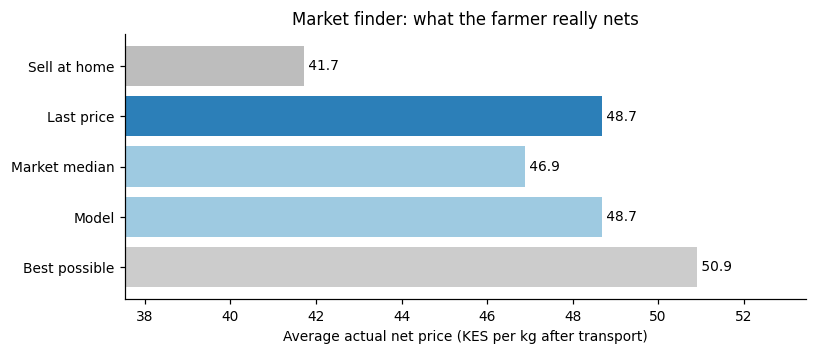

In [12]:
rows = []
for crop in sorted(cases.crop.unique()):
    cc = cases[cases.crop == crop]
    r, ch = evaluate(cc)
    rows.append({"crop": crop, "cases": len(ch["Best possible"]), "home net KES/kg": r.loc["Sell at home", "actual net price KES/kg"],
                 "model net KES/kg": r.loc["Model", "actual net price KES/kg"], "gain vs home (model)": r.loc["Model", "gain vs selling at home"],
                 "gain vs home (best possible)": r.loc["Best possible", "gain vs selling at home"],
                 "picks the best market %": r.loc["Model", "picks the best market %"]})
display(pd.DataFrame(rows).set_index("crop").round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.3))
names = list(mf.index); vals = mf["actual net price KES/kg"].values
ax.barh(names[::-1], vals[::-1], color=["#bdbdbd", "#2c7fb8", "#9ecae1", "#9ecae1", "#cccccc"][::-1])
for i, v in enumerate(vals[::-1]): ax.text(v, i, f" {v:.1f}", va="center")
ax.set_xlim(vals.min() * 0.9, vals.max() * 1.05); ax.set_xlabel("Average actual net price (KES per kg after transport)"); ax.set_title("Market finder: what the farmer really nets")
plt.tight_layout(); plt.show()

**Reading the market finder results.**

- **Using the current prices of nearby markets helps.** Over 341 farmer cases, selling at home nets KES 41.7 per kg after transport. Choosing the market by *expected price minus transport* nets KES 48.7: a gain of **KES 7.0 per kg (about 17%), 95% interval KES 5.4 to 8.7**. It is better than selling at home in 43% of cases, picks the best market 74% of the time (46% for always staying home), and captures about three quarters of the gain a perfect hindsight choice (KES 50.9) would give.
- **The model adds nothing beyond the last reported price.** Choosing by the last price gives the same result (KES 48.70 against 48.69, a difference of about zero), because the history-only model predicts almost exactly the last price. A long-run market median is worse (KES 46.9). The benefit comes from *using current prices* and *netting off transport*, not from the forecasting model.
- **The conclusion holds on a larger sample.** Counting cases with only one alternative market (1,301 cases) the gain is KES 4.8 per kg for both the model and the last price.
- **By crop.** Tomatoes gain KES 11.3 per kg (111 cases) and white potatoes KES 13.3 (35 cases); carrots gain KES 3.6 (167 cases). Cabbages (20 cases) and red potatoes (8 cases) are too few to judge.
- **Caveats.** The "actual" price at a candidate market is its recorded wholesale price that day, not what *this* farmer could get for their volume and quality, and if many farmers moved to the same market its price would fall. Transport uses the assumed pickup cost and road factor. Only market pairs with reliable coordinates were used, and the test covers only the latest months.

## 7. Saving the models for the app

For the app, models are fitted using the full available dataset, with a chronological calibration subset. Historical test metrics above refer only to the earlier held-out evaluation. The bundle also holds the latest known state of each crop and market (last price and date, long-run medians) and the distance table, so the functions in `price_ai.py` can answer a question from a crop, a market and an offer alone.

### Export and deploy the trained model
The existing mobile API uses `outputs/price_ai.py`. Export the fitted coefficients and market state into its model bundle so the demonstration uses the same inference functions as the Android application.

In [13]:
final = {}
for crop, g in u.groupby("crop"):
    for variant, feats in [("A", FEATS_A), ("B", FEATS_B)]:
        subset = g if variant == "A" else g.dropna(subset=["retail_kes_kg"])
        models, Q = fit_variant(subset, feats)
        final[(crop, variant)] = (models, Q, feats)
obs = d.dropna(subset=["wholesale_kes_kg"]).sort_values("date")
state = obs.groupby(["crop", "market"]).agg(
    county=("county", "last"), last_wholesale=("wholesale_kes_kg", "last"),
    last_date=("date", "last"), market_median=("wholesale_kes_kg", "median"), n_prices=("wholesale_kes_kg", "size")).reset_index()
county_medians = obs.groupby(["crop", "county"]).wholesale_kes_kg.median().rename("county_median").reset_index()
state = state.merge(county_medians, on=["crop", "county"])
joblib.dump({"models": final, "state": state, "pairs": pairs, "locations": loc,
             "data_end": d.date.max()}, OUT_DIR / "price_models.joblib")

import sys
sys.path.insert(0, str(OUT_DIR.resolve()))
import price_ai
price_ai.export_bundle(OUT_DIR / "price_models.joblib", OUT_DIR / "model_bundle")
print("Exported retrained models to the app's plain-file bundle.")


Exported retrained models to the app's plain-file bundle.


### 3.2 Live demonstration — farmer selling produce
Change the crop, market and buyer offer. The demo uses the latest date in the historical dataset, not today's live market prices. Run with and without a retail price to illustrate the two variants. Market ranking uses reliable road-distance estimates and pickup costs only.

In [14]:
CROP = "Tomatoes"
MARKET = "Kerugoya"
OFFER = 15  # KES/kg
RETAIL = 60 # optional retail price in KES/kg
AS_OF = d.date.max()  # historical demonstration, not live market data
print("Historical demonstration date:", AS_OF.date())
print("Without retail price:")
display(price_ai.offer_check(CROP, MARKET, OFFER, as_of=AS_OF))
print("With retail price:")
display(price_ai.offer_check(CROP, MARKET, OFFER, retail=RETAIL, as_of=AS_OF))
print("Alternative markets (maximum price age: 90 days):")
options = price_ai.find_markets(CROP, MARKET, as_of=AS_OF, top=3, max_stale_days=90)
display(options)
p = price_ai.predict_wholesale(CROP, MARKET, retail=RETAIL, as_of=AS_OF)
assert 0 < p["low"] <= p["expected"] <= p["high"]
assert price_ai.offer_check(CROP, MARKET, 0, as_of=AS_OF)["verdict"] == "low"
assert price_ai.offer_check(CROP, MARKET, p["expected"], as_of=AS_OF)["verdict"] == "good"
assert options.last_price_age_days.le(90).all()
print("Price range, offer verdict and market freshness checks passed.")

Historical demonstration date: 2026-10-28
Without retail price:


{'verdict': 'good',
 'offer': 15,
 'offer_as_share_of_wholesale': 0.6,
 'expected_wholesale': 25.0,
 'wholesale_range': (20.5, 36.4),
 'fair_offer_range': (8.8, 13.0),
 'inputs': 'price history only',
 'price_data_age_days': 9,
 'message': 'The offer is GOOD, above the expected range.'}

With retail price:


{'verdict': 'fair',
 'offer': 15,
 'offer_as_share_of_wholesale': 0.51,
 'expected_wholesale': 29.5,
 'wholesale_range': (24.6, 40.0),
 'fair_offer_range': (10.3, 15.3),
 'inputs': 'price history + retail price',
 'price_data_age_days': 9,
 'message': 'The offer is within the expected range.'}

Alternative markets (maximum price age: 90 days):


,market,county,road_km,expected_price,price_range,transport_per_kg,net_price,last_price_age_days,location_note
0,Makutano Kirinyaga,Kirinyaga,14.4,40.0,31 to 51,1.8,38.2,8,approximate distance
1,Ngurubani Market,Kirinyaga,28.8,37.5,30 to 42,3.6,33.9,2,
2,Mukuyu Market,Muranga,37.0,35.0,25 to 49,4.7,30.3,20,


Price range, offer verdict and market freshness checks passed.


## 8. What can honestly be claimed

| Claim the group might want to make | Can it be made? | Evidence |
|---|---|---|
| "The model predicts wholesale prices to 95% accuracy" | **No** | Average error is 14% (MAPE is not classification accuracy). Prices are rounded and noisy |
| "The historical model has about 14% MAPE and predicts within 10% of the actual price in 55% of cases" | **Yes** | Section 4, test set of 4,387 market-days |
| "The predicted price range contains the actual price about 80% to 85% of the time" | **Yes** | 85% overall, 81% to 89% by crop |
| "The model is better than just using the last price" | **Only slightly, and only with the retail price** | 14.0% against 14.9% error; with history only the expected price equals the last price |
| "The offer checker detects low offers" | **Conditionally** | Clear for offers well below the band, blurred near its edge; the verdict rests on an assumed farmer's-share band |
| "The market finder increases what the farmer nets" | **Yes** | +KES 7.0 per kg (95% interval 5.4 to 8.7) over selling at home, in 341 test cases; but equal to copying the last price |

**Limits to state in the report**
1. KAMIS has no farm-gate prices, so the offer checker rests on an **assumed farmer's-share band** (default 35% to 52%, from a 2009 to 2010 potato study). It must be replaced with a benchmark the group can defend, ideally from farmer survey data or better literature.
2. The model gives a **range with an expected price**, not an exact price, and the range is wide (high is about 1.5 to 1.9 times low).
3. Performance falls when the last price is old (over 30 days) and the app must show the age of the price.
4. The market finder test has only 341 cases (3 or more candidate markets) and used only markets with reliable coordinates; 99 markets still have approximate locations.
5. Cabbages (four-month test period) and red potatoes (few market-finder cases) are the least certain.
6. Everything was tested on historical data; no farmer has used it yet.

**What was tried and dropped.** Same-day prices from other markets (county and national) added almost nothing and were left out. A more complex model (for example gradient boosting) was not tried because the group chose linear quantile regression and the data's noise floor (rounded prices, 44% unchanged) limits any model.

**Next steps.** (1) Fix the farmer's-share benchmark. (2) Re-export the missing KAMIS periods and re-run, which would give a longer test period and a better look at seasonality. (3) Locate the busiest markets that still have approximate coordinates. (4) Decide whether the advisory dataset or a small field trial comes next.

# 3. Crop advisory — data preparation and retrieval prototype
The original data preparation workflow is retained. The original notebook reported 5,745 cleaned rows, but the CSV itself was not in the ZIP. Advisory training and evaluation have not been rerun.

## 1. Setup and data sources

In [15]:
import re, json, time, hashlib, unicodedata, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# Use the same project outputs folder as the price engine.
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
DOWNLOAD_ADVISORY_DATA = False  # set True only with internet access
CACHED_ADVISORY = (OUT_DIR / "crop_qa_clean.csv").exists()
RUN_RAW_ADVISORY = DOWNLOAD_ADVISORY_DATA and not CACHED_ADVISORY
RUN_ADVISORY = CACHED_ADVISORY or RUN_RAW_ADVISORY
if not RUN_ADVISORY:
    print("Advisory pending: add outputs/crop_qa_clean.csv or enable the download option.")


In [16]:
# ---- Parameters, set once here so they can be changed and the notebook re-run ----------------------------------
# Target crops. English and Swahili names; "sweet potato / viazi vitamu" is deliberately NOT a match for potato.
CROPS = {
    "cabbage": r"\b(?:cabbages?|kabichi)\b",
    "tomato":  r"\b(?:tomato(?:es)?|nyanya)\b",
    "potato":  r"(?<!sweet )\b(?:potato(?:es)?|viazi(?!\s+vitamu))\b",
    "carrot":  r"\b(?:carrots?|karoti)\b",
}
CROP_RE = {k: re.compile(v, re.I) for k, v in CROPS.items()}

TOPICS = {   # checked in this order; the first hit is the primary topic
    "fertilizer": r"fertili[sz]er|\bnpk\b|\burea\b|\bdap\b|\bmop\b|\bssp\b|calcium ammonium|manure|compost|nutrient|micronutrient|deficien|nitrogen|phosph|potash|potassium|calcium|boron",
    "disease":    r"blight|wilt|\brot\b|mildew|\brust|spot|mosaic|virus|fung|bacteri|canker|scab|disease|symptom|lesion|yellowing|curl",
    "pest":       r"pest|insect|aphid|whitefl|worm|caterpillar|borer|mite|thrips|nematode|beetle|moth|cutworm|\bfly\b|\bflies\b",
    "season":     r"season|\bsow|plant(?:ing)? time|when to plant|transplant|harvest|month|rainy|monsoon|long rains|short rains|winter|summer",
    "practice":   r"cultural|cultivation|spacing|irrigat|water|mulch|rotation|weed|soil|variet|seed|prun|stak",
}
TOPIC_RE = {k: re.compile(v, re.I) for k, v in TOPICS.items()}
LABEL_TOPIC = {"symptoms": "disease", "conditions": "disease"}   # labels in Farm_QA_Dataset that map to a topic directly

MIN_Q_LEN, MIN_A_LEN = 12, 25     # characters; shorter text cannot carry a usable question or answer
TEST_SHARE = 0.10                 # share of answer-groups held out for testing (section 7)
USE_GENERATED = False             # LLM-generated Q&A: off by default because of factual errors

# Answers that carry no information (very common in call-centre style data)
LOW_INFO = re.compile(
    r"^\W*(?:"
    r"(?:explain(?:ed)?|answer|given|forwarded|transfer(?:red)?|details?)\b(?=.{0,70}$)(?=.*\b(?:details?|detailed|expert|given|forwarded|contact)\b)"
    r"|suggest(?:ed)?\s+him\s+the\b(?=.{0,70}$)"
    r")", re.I)

# Typos seen in the call-centre data -> corrected form
TYPO_FIXES = {r"\bfertilidose\b": "fertilizer dose", r"\brecommanded\b": "recommended", r"\bcultral\b": "cultural",
              r"\bpractise\b": "practice", r"\bapplicatio\b": "application", r"\badviced\b": "advised",
              r"\brequirment\b": "requirement", r"\bbraod\b": "broad", r"\bcuper oxyclorides?\b": "copper oxychloride",
              r"\bridomill\b": "ridomil"}

URL_RE   = re.compile(r"https?://\S+|www\.\S+", re.I)
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
PHONE_RE = re.compile(r"(?<!\d)(?:\+?254|0)[17]\d{2}[\s\-]?\d{3}[\s\-]?\d{3}(?!\d)|(?<!\d)\+\d{1,3}[\s\-]?\d{2,4}[\s\-]?\d{3}[\s\-]?\d{3,4}(?!\d)")
QUANTITY_RE = re.compile(r"\d+(?:[.,]\d+)?\s*(?:kg|kgs|gm?|gms|grams?|ml|l|lit(?:re|er)s?|ppm|%|t/ha|tonnes?|bags?)(?![A-Za-z])", re.I)
REGION_RE   = re.compile(r"\b(?:bigha|katha|gunta|rupees?|lakh|crore|mandi|kisan|imd|panchayat|rs)\b", re.I)

# ---- Text helpers ------------------------------------------------------------------------------------------------
def norm(t):
    """Unicode-normalise, drop 'questions:'/'answers:' prefixes and literal newlines, collapse whitespace."""
    if t is None or (isinstance(t, float) and np.isnan(t)): return ""
    t = unicodedata.normalize("NFKC", str(t))
    t = t.replace("\\n", " ")                 # a literal backslash-n sequence present in some exports
    t = re.sub(r"[\r\n\t]+", " ", t)
    t = re.sub(r"^(?:questions?|answers?)\s*:\s*", "", t.strip(), flags=re.I)
    return re.sub(r"\s+", " ", t).strip()

def qkey(s):
    """Key for comparing questions: lower case, letters and digits only."""
    return re.sub(r"\W+", " ", str(s).lower()).strip()

def detect_crops(text):
    return [c for c, rx in CROP_RE.items() if rx.search(text or "")]

def scope_crops(question, crop_label=None):
    """A crop label from the source wins over text matching. Without a label only the QUESTION is searched,
    because answers often mention other crops in passing (e.g. 'rotate with cabbage and potato')."""
    lab = norm(crop_label) if crop_label is not None else ""
    if lab and lab.lower() not in {"nan", "none"}:
        return detect_crops(lab)
    return detect_crops(norm(question))

def topics_of(text):
    return [k for k, rx in TOPIC_RE.items() if rx.search(text or "")]
print("parameters and helpers ready")

parameters and helpers ready


**Sources.** (1) `Rahulrayudu/Farm_QA_Dataset`, a structured Q&A set with a crop column and a label (Symptoms, Conditions, ...); (2) `SivaResearch/Agri`, farmer call-centre questions and agent answers (India); (3) `Sunny6727/knowledge_base`, a small JSON of crop diseases; (4) optionally `Vrushali/generated_chat` (LLM-generated, off by default); (5) scraped extension pages (Kenyan sources, added by you in section 2.1). All of them are **text only**, no images.

**Known limitations of the sources, discovered during exploration:** the public sets are mostly Indian (units such as *bigha*, products sold under Indian brand names), many call-centre answers are empty of content ("explained in details"), and the same fact is often written many times as paraphrases. Together these shape the whole cleaning exercise.

## 2. Exploring the raw data

### 2.1 What sources do we have and what do they cover?

In [17]:
if RUN_RAW_ADVISORY:
    raw_records = []    # one dict per Q&A row, nothing filtered yet (scope filtering is cleaning step 3)

    def add_raw(question, answer, source, region, crop_label=None, label=None):
        raw_records.append(dict(question=question, answer=answer, source=source, region=region, crop_label=crop_label, label=label))

    def find_cols(df):
        cols = {c.lower(): c for c in df.columns}
        q = next((cols[c] for c in cols if any(k in c for k in ("question", "query", "prompt"))), None)
        a = next((cols[c] for c in cols if any(k in c for k in ("answer", "response", "output"))), None)
        return q, a

    def load_hf(name, split="train"):
        try:
            from datasets import load_dataset
            return load_dataset(name, split=split).to_pandas()
        except Exception as e:
            print(f"[skip] {name}: {e}")
            return None


In [18]:
if RUN_RAW_ADVISORY:
    # Source 1: Farm_QA_Dataset has Crop / Label / Question / Answer columns
    d = load_hf("Rahulrayudu/Farm_QA_Dataset")
    if d is not None:
        print(d.columns.tolist(), len(d))
        for r in d.to_dict("records"):
            add_raw(r.get("Question"), r.get("Answer"), "Rahulrayudu/Farm_QA_Dataset", "global", crop_label=r.get("Crop"), label=r.get("Label"))
    print("raw rows so far:", len(raw_records))


In [19]:
if RUN_RAW_ADVISORY:
    # Source 2: SivaResearch/Agri, farmer call-centre Q&A (India)
    d = load_hf("SivaResearch/Agri")
    if d is not None:
        print(d.columns.tolist(), len(d))
        q, a = find_cols(d)
        if q and a:
            for r in d[[q, a]].itertuples(index=False):
                add_raw(r[0], r[1], "SivaResearch/Agri", "india")
        else:   # fall back: one text column holding 'questions: ... answers: ...'
            for t in d[d.columns[0]].astype(str):
                m = re.search(r"questions?\s*:\s*(.*?)\s*answers?\s*:\s*(.*)", t, re.I | re.S)
                if m: add_raw(m.group(1), m.group(2), "SivaResearch/Agri", "india")
    print("raw rows so far:", len(raw_records))


In [20]:
if RUN_RAW_ADVISORY:
    # Source 3: Sunny6727/knowledge_base (small JSON, nested under crop_diseases)
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Sunny6727/knowledge_base", "knowledge_base.json", repo_type="model")
        kb = json.load(open(p))
        for crop, items in kb.get("crop_diseases", {}).items():
            for it in items:
                ans = f"Symptoms: {it.get('symptoms','')}. Treatment: {it.get('treatment','')}. Prevention: {it.get('prevention','')}."
                add_raw(f"What are the symptoms and treatment of {it['disease']} in {crop}?", ans, "Sunny6727/knowledge_base", "global",
                        crop_label=crop, label="disease")
        for qa in kb.get("faq", kb.get("qa", [])):
            add_raw(qa.get("question"), qa.get("answer"), "Sunny6727/knowledge_base", "global")
    except Exception as e:
        print("[skip] knowledge_base:", e)
    print("raw rows so far:", len(raw_records))


In [21]:
if RUN_RAW_ADVISORY:
    # Source 4 (optional): LLM-generated Q&A. Off by default because it contains factual errors
    # (e.g. a pesticide name described as a plant disease). Switch USE_GENERATED on in section 1 to include it.
    if USE_GENERATED:
        d = load_hf("Vrushali/generated_chat")
        if d is not None:
            q, a = find_cols(d)
            for r in d[[q, a]].itertuples(index=False):
                add_raw(r[0], r[1], "Vrushali/generated_chat (LLM-generated)", "india")
    print("raw rows so far:", len(raw_records))


**Source 5: scraped extension pages.** Public datasets are thin on **Kenya-specific** advice, so this cell lets you add pages from sources you trust and are allowed to use (KALRO and Ministry of Agriculture guides, CABI PlantwisePlus factsheets, university extension sites, FAO crop guides). Each page is split into heading -> text sections and every section becomes one Q&A row. **Check each site's terms and robots.txt, and keep the source label so the data can be credited.** The cell does nothing while `SCRAPE_URLS` is empty.

In [22]:
if RUN_RAW_ADVISORY:
    import requests
    from bs4 import BeautifulSoup
    from urllib import robotparser
    from urllib.parse import urlparse

    SCRAPE_URLS = [
        # (url, crop, source_label, region)   e.g. ("https://.../tomato-late-blight", "tomato", "KALRO", "kenya")
    ]
    HEADERS = {"User-Agent": "crop-qa-research-bot/0.1 (contact: you@example.com)"}

    def allowed(url):
        p = urlparse(url)
        rp = robotparser.RobotFileParser()
        try:
            rp.set_url(f"{p.scheme}://{p.netloc}/robots.txt"); rp.read()
            return rp.can_fetch(HEADERS["User-Agent"], url)
        except Exception:
            return False

    def scrape_page(url, crop, label, region="kenya"):
        if not allowed(url):
            print("[robots disallow / unreachable]", url); return 0
        soup = BeautifulSoup(requests.get(url, headers=HEADERS, timeout=30).text, "lxml")
        for t in soup(["script", "style", "nav", "footer", "header", "aside", "form"]): t.decompose()
        title = (soup.find("h1") or soup.title or soup).get_text(" ", strip=True)[:150]
        state = {"section": "Overview", "buf": [], "n": 0}
        def flush():
            text = norm(" ".join(state["buf"]))
            if len(text) > 80:
                q = f"{state['section']} of {title} in {crop}?" if state["section"] != "Overview" else f"Tell me about {title} in {crop}."
                add_raw(q, text, f"scrape:{label}:{url}", region, crop_label=crop)
                state["n"] += 1
        for el in soup.find_all(["h2", "h3", "p", "li"]):
            if el.name in ("h2", "h3"):
                flush(); state["buf"] = []; state["section"] = el.get_text(" ", strip=True)
            else:
                state["buf"].append(el.get_text(" ", strip=True))
        flush()
        return state["n"]

    for url, crop, label, *rest in SCRAPE_URLS:
        n = scrape_page(url, crop, label, *(rest or ["kenya"])); print(f"{n:3d} sections  {url}"); time.sleep(2)   # be polite
    print("raw rows so far:", len(raw_records))


In [23]:
if RUN_RAW_ADVISORY:
    assert raw_records, "no source could be loaded: check the internet connection and the messages above"
    raw = pd.DataFrame(raw_records)
    blank = lambda s: s.isna() | s.astype(str).str.strip().isin(["", "nan", "None", "-"])
    raw["crop_guess"] = [(scope_crops(q, l) or ["(out of scope)"])[0] for q, l in zip(raw.question, raw.crop_label)]
    inventory = raw.groupby("source").agg(region=("region", "first"), rows=("question", "size"),
                                          blank_answers=("answer", lambda s: int(blank(s).sum())),
                                          in_scope_rows=("crop_guess", lambda s: int((s != "(out of scope)").sum()))).reset_index()
    inventory["in_scope_%"] = (inventory.in_scope_rows / inventory.rows * 100).round(1)
    inventory


**Finding.** Read the `in_scope_%` column: it is the share of each source that is about cabbage, tomato, potato or carrot. Broad sources (several dozen crops) will be mostly out of scope, which is expected; the target-crop rows are what survive step 3. A source with a very small `in_scope_rows` contributes little however large it is.

Rows about crops other than the four study crops (and sweet potatoes, which are a different crop from Irish potatoes) are excluded from here on.

### 2.2 Structure and data types

In [24]:
if RUN_RAW_ADVISORY:
    raw.info()
    print()
    raw.sample(6, random_state=1)[["source", "crop_label", "label", "question", "answer"]]


**Finding.** Every field is *text*, and the sources do not agree on structure: one has a crop and a label column, the others only a question and an answer, and some have `questions:` / `answers:` prefixes and literal `\n` sequences inside the text. Nothing can be compared or de-duplicated until the text is normalised, and the crop has to be derived from the text for the sources without a crop column.

### 2.3 Data quality audit (before touching anything)

In [25]:
if RUN_RAW_ADVISORY:
    q, a = raw.question.astype(str), raw.answer.astype(str)
    qn, an = q.map(norm), a.map(norm)
    pairs = pd.DataFrame({"k": qn.map(qkey), "a": an})
    text = qn + " " + an
    audit = {
        "rows per source": raw.source.value_counts().to_dict(),
        "blank question": int(blank(q).sum()),
        "blank answer": int(blank(a).sum()),
        "answers with no information ('explained in details', 'forwarded to the expert', ...)": int(an.map(lambda s: bool(LOW_INFO.match(s))).sum()),
        f"answers shorter than {MIN_A_LEN} characters": int((an.str.len() < MIN_A_LEN).sum()),
        "text with a literal '\\n' or a 'questions:' / 'answers:' prefix": int((q.str.contains(r"\\n|^\s*questions?\s*:", case=False, regex=True) |
                                                                               a.str.contains(r"\\n|^\s*answers?\s*:", case=False, regex=True)).sum()),
        "answers containing a URL, e-mail or phone number": int(an.map(lambda s: bool(URL_RE.search(s) or EMAIL_RE.search(s) or PHONE_RE.search(s))).sum()),
        "exact duplicate rows (same question and answer)": int(pairs.duplicated().sum()),
        "questions that appear more than once with DIFFERENT answers": int((pairs.groupby("k")["a"].nunique() > 1).sum()),
        "rows mentioning a target crop anywhere (question or answer)": {c: int(text.str.contains(v, case=False, regex=True).sum()) for c, v in CROPS.items()},
        "rows mentioning sweet potato / viazi vitamu": int(text.str.contains(r"sweet\s+potato|viazi\s+vitamu", case=False, regex=True).sum()),
        "known typos found (rows per pattern)": {p: int(an.str.contains(p, case=False, regex=True).sum()) for p in TYPO_FIXES if an.str.contains(p, case=False, regex=True).any()},
    }
    for k, v in audit.items():
        print(f"{k}: {v}")


In [26]:
if RUN_RAW_ADVISORY:
    # Distribution of text lengths by source: where do the very short answers come from?
    raw["answer_chars"], raw["question_chars"] = an.str.len().values, qn.str.len().values
    raw.groupby("source").agg(q_median=("question_chars", "median"), a_p10=("answer_chars", lambda s: s.quantile(.1)),
                              a_median=("answer_chars", "median"), a_p90=("answer_chars", lambda s: s.quantile(.9))).round(0)


**Findings.**
- The call-centre source contains many answers that say nothing ("explained in details", "answer is given in details", "forwarded to the expert"). They look like valid rows but teach a chatbot to reply with an empty sentence.
- Typos are frequent and sometimes change the meaning of a product or a word (`fertilidose`, `recommanded`, `cuper oxyclorides`).
- There are exact duplicates, and also the *same question with different answers*, often because several agents answered differently or because a source repeats a question as a paraphrase.
- Crops are mentioned in passing inside answers (for example a chilli answer that says "rotate with cabbage and potato"). Matching on the whole row would wrongly pull such rows into scope, which is why step 3 matches the **question** (or the crop label of the source).
- Some answers carry doses in local units (*bigha*) and other region-specific wording; they are handled in section 6, not deleted.

### 2.4 Crop names

In [27]:
if RUN_RAW_ADVISORY:
    surface = Counter()
    for s in raw.question.map(norm):
        for c, rx in CROP_RE.items():
            surface.update((c, m.lower()) for m in rx.findall(s))
    names = pd.DataFrame([{"crop": c, "form found in the question": f, "rows": n} for (c, f), n in surface.most_common()])
    print("distinct name forms found in questions:")
    display(names)

    # Do the crop label of a source and the crop named in the question ever disagree?
    both = raw[raw.crop_label.notna()].copy()
    both["lab"] = both.crop_label.map(lambda s: sorted(detect_crops(norm(s))))
    both["qc"] = both.question.map(lambda s: sorted(detect_crops(norm(s))))
    dis = both[(both.lab.map(len) > 0) & (both.qc.map(len) > 0) & (both.lab.map(tuple) != both.qc.map(tuple))]
    print(f"\nrows where the labelled crop and the crop in the question disagree: {len(dis)} of {len(both)} labelled rows")
    print("questions that name more than one target crop:", int((raw.question.map(lambda s: len(detect_crops(norm(s)))) > 1).sum()))
    dis[["crop_label", "question"]].head(8)


**Finding.** A name audit (English plural forms, Swahili names such as *kabichi*, *nyanya*, *viazi*, *karoti*, and the sweet-potato exclusion) is the basis of the `CROPS` patterns in section 1. Where the source supplies a crop label it is trusted over the text. A question that names two target crops is kept and tagged `multiple` instead of being forced into one crop. Name matching is a judgement call, which is why the patterns are explicit and editable.

### 2.5 Coverage by crop and source (where is the history thin?)

In [28]:
if RUN_RAW_ADVISORY:
    cov = pd.crosstab(raw.crop_guess, raw.source)
    cov = cov.drop(index="(out of scope)", errors="ignore")
    ax = cov.plot.barh(stacked=True, figsize=(10, 3.2), colormap="tab20")
    ax.set_xlabel("raw rows"); ax.set_title("In-scope raw rows per crop, by source")
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    plt.tight_layout(); plt.show()
    cov.assign(total=cov.sum(axis=1))


**Finding.** Coverage is *uneven*. One crop usually has several times more rows than another, and one source tends to supply most of them. Carrots are likely to be the thinnest crop in the public sets (check the table). This is a **data-acquisition problem that cleaning does not solve**; it is carried forward as a limitation (section 9) and the fix is to add scraped Kenyan pages for the thin crops (section 2.1, source 5).

## 3. Cleaning pipeline

Each step below is applied to the same data frame in order, and the number of rows after each step is recorded in `log` so that the whole process can be audited as a waterfall. The parameters (minimum lengths, typo table, crop patterns, no-information pattern) are set once in section 1, so they can be changed and the notebook re-run.

In [29]:
if RUN_RAW_ADVISORY:
    log = []
    def record(step, df, note=""):
        log.append({"step": step, "rows": len(df), "note": note})

    df = raw.drop(columns=["crop_guess", "answer_chars", "question_chars"]).copy()
    record("0. Raw rows loaded (all sources)", df)


### Step 1 and 2: Normalise the text and drop blank rows
Questions and answers are Unicode-normalised, the `questions:` / `answers:` prefixes and literal `\n` sequences are removed, and whitespace is collapsed. Rows whose question or answer is empty after that are dropped.

*Alternative considered:* keep blank answers and fill them from another source. Rejected: there is no way to know that the other answer fits the same question.

In [30]:
if RUN_RAW_ADVISORY:
    df["question"], df["answer"] = df["question"].map(norm), df["answer"].map(norm)
    for c in ("source", "region"):
        df[c] = df[c].astype(str).str.strip()
    n_blank = int(((df.question == "") | (df.answer == "")).sum())
    df = df[(df.question != "") & (df.answer != "")].copy()
    record("1-2. Normalise text, drop blank questions and answers", df, f"{n_blank} blank rows removed")
    print("blank rows removed:", n_blank)


### Step 3: Keep only the four target crops
The crop is taken from the source's crop label when there is one, otherwise from the **question** text (English and Swahili names, sweet potato excluded). A row that names two target crops gets the crop `multiple`. Everything else (other crops, no crop named) is removed.

*Why the question and not the answer:* answers mention other crops in passing (rotation advice, "also affects potato"), and matching them would bring in rows that are really about chilli or maize.
*Risk:* a question that never names the crop ("what fertilizer should I apply?") is lost even when the answer is about tomatoes. Those rows cannot be used safely, because the chatbot would not know which crop the advice is for.

In [31]:
if RUN_RAW_ADVISORY:
    n0 = len(df)
    found = [scope_crops(q, l) for q, l in zip(df.question, df.crop_label)]
    df["crops_found"] = [",".join(f) for f in found]
    df = df[df.crops_found != ""].copy()
    df["crop"] = np.where(df.crops_found.str.contains(","), "multiple", df.crops_found)
    record("3. Keep in-scope crops (cabbage, tomato, potato, carrot)", df, f"{n0 - len(df)} out-of-scope rows removed; {int((df.crop == 'multiple').sum())} rows name several crops")
    print("out-of-scope rows removed:", n0 - len(df))
    print(df.crop.value_counts().to_dict())


### Step 4: Tag the topic (disease, pest, fertilizer, season, practice)
`topic` is the primary topic: the source's label if it maps to one (`Symptoms`, `Conditions` -> disease), otherwise the first topic whose keywords appear in the **question** (and in the answer if the question matches none). `topics_all` keeps every topic found, because a row such as "fertilizer for blight-affected potato" is about two things.

*Alternative considered:* train a small classifier. Rejected for now: keyword rules are transparent and can be checked by reading rows; a classifier needs labelled data we do not have.
*Risk:* keywords overlap (`water` is also a symptom of rot), so some rows will get a debatable primary topic. `topics_all` limits the damage.

In [32]:
if RUN_RAW_ADVISORY:
    prim = []
    for q, a, lab in zip(df.question, df.answer, df.label):
        hits = topics_of(q) or topics_of(a)
        t = LABEL_TOPIC.get(norm(lab).lower())
        prim.append(t or (hits[0] if hits else "other"))
    df["topic"] = prim
    df["topics_all"] = [";".join(topics_of(q + " " + a)) for q, a in zip(df.question, df.answer)]
    record("4. Tag topic (no rows removed)", df, f"{int((df.topic == 'other').sum())} rows have no recognised topic")
    print(df.topic.value_counts().to_dict())


### Step 5: Remove answers that carry no information, and text that is too short
An answer is removed when it matches the *no-information* pattern (`explained in details`, `forwarded to the expert`, `suggest him the fertilizer dose for potato`), or when the question is shorter than `MIN_Q_LEN` or the answer shorter than `MIN_A_LEN` characters.

*Why it matters:* a fine-tuned model imitates its training answers. If one in five answers is "explained in details", it will often reply with that.
*Risk:* the pattern only fires on **short** answers that also contain a give-away word, so a genuine short answer such as "advised to spray 2,4-D at 10 ppm" is kept. A very short but real answer below `MIN_A_LEN` is lost.

In [33]:
if RUN_RAW_ADVISORY:
    n0 = len(df)
    low = df.answer.map(lambda s: bool(LOW_INFO.match(s)))
    short = (df.question.str.len() < MIN_Q_LEN) | (df.answer.str.len() < MIN_A_LEN)
    df = df[~(low | short)].copy()
    record("5. Remove no-information and too-short rows", df, f"{int(low.sum())} no-information answers; {int(short.sum())} too short (the two groups may overlap)")
    print("no-information answers:", int(low.sum()), "| too short:", int(short.sum()), "| removed in total:", n0 - len(df))


### Step 6: Scrub contact details and fix typos
URLs, e-mail addresses and phone numbers are deleted from the text (they identify people and shops, not agronomy). Known typos are corrected using `TYPO_FIXES`. The length filter is applied again afterwards, because deleting a URL can leave a very short answer.

*Alternative considered:* a spell-checker library. Rejected: it would "correct" product names (Ridomil, Indofil) and Swahili words into ordinary English.
*Risk:* the typo table only fixes what has been seen; new typos in new sources need to be added.

In [34]:
if RUN_RAW_ADVISORY:
    def scrub(t):
        t = PHONE_RE.sub("", EMAIL_RE.sub("", URL_RE.sub("", t)))
        return re.sub(r"\s+", " ", t).strip()

    before = df[["question", "answer"]].copy()
    df["question"], df["answer"] = df.question.map(scrub), df.answer.map(scrub)
    for pat, rep in TYPO_FIXES.items():
        df["question"] = df.question.str.replace(pat, rep, regex=True, flags=re.I)
        df["answer"] = df.answer.str.replace(pat, rep, regex=True, flags=re.I)
    n_changed = int(((before.question != df.question) | (before.answer != df.answer)).sum())
    n0 = len(df)
    df = df[(df.question.str.len() >= MIN_Q_LEN) & (df.answer.str.len() >= MIN_A_LEN)].copy()
    record("6. Scrub contact details, fix typos", df, f"{n_changed} rows edited; {n0 - len(df)} became too short and were removed")
    print("rows edited:", n_changed, "| removed afterwards:", n0 - len(df))


### Step 7: One row per crop and question
Two things are done, in this order. First, exact duplicates (same crop, same question, same answer) are removed. Second, when the same question still appears more than once with different answers (several agents, several sources), the rows are collapsed to one, keeping the **longest** answer. The number of rows that were merged is stored in `n_variants`.

*Why:* repeated questions with different answers teach the model to contradict itself, and duplicates inflate any score measured on a test set.
*Cost:* the longest answer is not always the best one (it may be the wordiest, or from a generated source), and the other agents' wording is lost. *Improvement:* rank the sources by trust and keep the best-ranked answer instead of the longest.

In [35]:
if RUN_RAW_ADVISORY:
    n0 = len(df)
    df["_k"] = df.question.map(qkey)
    df = df.drop_duplicates(["crop", "_k", "answer"]).copy()
    n_exact = n0 - len(df)
    df["n_variants"] = df.groupby(["crop", "_k"])["answer"].transform("size")
    n1 = len(df)
    df = df.assign(_alen=df.answer.str.len()).sort_values("_alen", ascending=False).drop_duplicates(["crop", "_k"]).drop(columns="_alen")
    record("7. Drop exact duplicates, one row per crop and question", df, f"{n_exact} exact duplicates; {n1 - len(df)} repeated questions merged")
    print("exact duplicates removed:", n_exact, "| repeated questions merged:", n1 - len(df))


### Step 8: Flags and helper columns
- `has_quantity` flags answers that contain a number with a unit (`12 kg`, `2 ml per litre`, `10 ppm`).
- `region_specific` flags answers that contain local terms or units (*bigha*, rupees, *mandi*, *kisan*). They are **flagged, not deleted**, because the rest of the advice may still be valid.
- `needs_review` is `has_quantity` on a fertilizer, disease or pest answer. These are the rows where a wrong number can damage a crop, so a person should read them before the model is released.
- `answer_words` is a simple length measure used in the EDA.

In [36]:
if RUN_RAW_ADVISORY:
    df["has_quantity"] = df.answer.map(lambda s: bool(QUANTITY_RE.search(s)))
    df["region_specific"] = (df.question + " " + df.answer).map(lambda s: bool(REGION_RE.search(s)))
    df["needs_review"] = df.has_quantity & df.topic.isin(["fertilizer", "disease", "pest"])
    df["answer_words"] = df.answer.str.split().str.len()
    cols = ["crop", "topic", "topics_all", "question", "answer", "source", "region", "n_variants",
            "has_quantity", "region_specific", "needs_review", "answer_words", "crops_found"]
    clean = df[cols].sort_values(["crop", "topic", "question"]).reset_index(drop=True)
    record("8. Add flags and helper columns (no rows removed)", clean,
           f"{int(clean.region_specific.sum())} rows region-specific; {int(clean.needs_review.sum())} rows flagged for review")
    print("region-specific rows:", int(clean.region_specific.sum()), "| rows flagged for review:", int(clean.needs_review.sum()))


### The cleaning waterfall

In [37]:
if RUN_RAW_ADVISORY:
    wf = pd.DataFrame(log)
    wf["change"] = wf["rows"].diff().fillna(0).astype(int)
    display(wf)

    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.barh(wf["step"][::-1], wf["rows"][::-1], color="#2c7fb8")
    for i, v in enumerate(wf["rows"][::-1]): ax.text(v, i, f" {v:,}", va="center")
    ax.set_xlim(0, wf["rows"].max() * 1.15); ax.set_title("Rows remaining after each step")
    plt.tight_layout(); plt.show()


Rows fall mainly at **step 3 (scope)**, because most public rows are about other crops, and at **steps 5 and 7**, because of no-information answers and repeated questions. Steps 2, 4, 6 and 8 remove few or no rows. That is the expected shape; if step 3 removes almost nothing, the crop patterns are probably too loose, and if it removes almost everything, check the source column names printed in section 2.1.

## 4. Reconciliation and quality checks

In [38]:
if RUN_RAW_ADVISORY:
    # 4.1 Integrity checks on the cleaned data
    assert len(clean) > 0, "the cleaned dataset is empty"
    assert not clean.duplicated(["crop", "question"]).any(), "crop + question must be unique"
    assert (clean.question.str.len() >= MIN_Q_LEN).all() and (clean.answer.str.len() >= MIN_A_LEN).all()
    assert not clean.answer.map(lambda s: bool(URL_RE.search(s) or EMAIL_RE.search(s) or PHONE_RE.search(s))).any(), "contact details left in answers"
    assert not clean.answer.map(lambda s: bool(LOW_INFO.match(s))).any(), "no-information answers left"
    assert set(clean.crop) <= set(CROPS) | {"multiple"}, "unexpected crop value"
    assert not clean.question.str.contains(r"\\n").any() and not clean.answer.str.contains(r"\\n").any()
    print("unique crop-question key: OK | minimum lengths respected: OK | no contact details: OK | no empty answers: OK | crops:", sorted(clean.crop.unique()))

    # 4.2 Reconcile with the file produced by the earlier version of the notebook
    f = OUT_DIR / "crop_qa_clean.csv"
    if f.exists():
        ref = pd.read_csv(f)
        ref_keys = set(zip(ref["crop"].astype(str), ref["question"].map(qkey)))
        new_keys = set(zip(clean["crop"].astype(str), clean["question"].map(qkey)))
        print(f"earlier export: {len(ref):,} rows | this run: {len(clean):,} rows | questions in both: {len(ref_keys & new_keys):,} "
              f"| only in the earlier file: {len(ref_keys - new_keys):,} | only in this run: {len(new_keys - ref_keys):,}")
    else:
        print("crop_qa_clean.csv not found: reconciliation skipped")


In [39]:
if RUN_RAW_ADVISORY:
    # 4.3 What is thin in the final data?
    thin = pd.crosstab(clean.crop, clean.topic, margins=True)
    display(thin)
    print("rows per source:", clean.source.str.split(":").str[0].value_counts().to_dict())
    print("rows with a small question text (< 20 characters):", int((clean.question.str.len() < 20).sum()))


**Thin cells are not filled artificially.** If a crop-topic cell has few rows (for example carrot fertilizer), the notebook does *not* copy rows from another crop or generate paraphrases to fill it. That would make the chatbot answer carrot questions with tomato advice. The fix is more sources for that cell (section 2.1, source 5), and until then the chatbot should say it does not know.

## 5. Supporting data: scraped Kenyan extension pages (summary)

The scraped pages are the only source that can carry **Kenyan** conditions (long and short rains, local varieties, products sold in Kenya). Unlike the public sets they are small, so they are kept in the training data but are always **labelled** by `source` (`scrape:<label>:<url>`) and `region`, so that their effect can be measured separately and the pages can be credited. Their cleaning follows the same eight steps.

In [40]:
if RUN_RAW_ADVISORY:
    sc = clean[clean.source.str.startswith("scrape:")]
    if len(sc):
        sc = sc.assign(site=sc.source.str.split(":").str[1])
        display(sc.groupby(["site", "crop", "topic"]).agg(rows=("question", "size"), median_answer_words=("answer_words", "median")).round(0))
    else:
        print("no scraped rows in the cleaned data: add URLs to SCRAPE_URLS in section 2.1 to bring in Kenyan sources")
    print("share of the cleaned rows that come from scraped (Kenyan) pages: %.1f%%" % (len(sc) / len(clean) * 100))


**Check of the scrape.** Open 10 scraped rows and read them against the web page. A heading that is not a question ("Overview", "References", "Contact us") produces a nonsense Q&A pair; if you see any, add that heading to a skip list in `scrape_page`. Scraped text is also **copyrighted material**: keep it for your own training and retrieval, do not republish it, and credit the source.

## 6. Regional relevance and units

The chatbot is for Kenyan farmers, but most of the public rows come from India. Advice such as "urea 12 kg per bigha" is **not usable as written**: a *bigha* is not a Kenyan unit, and the rate differs per soil and crop variety. Rows are classified in two ways: by the `region` of their source (`global`, `india`, `kenya`, ...) and by `region_specific`, which is true when the text contains local terms or units. Nothing is converted automatically, because the conversion of a *bigha* varies between Indian states.

In [41]:
if RUN_RAW_ADVISORY:
    reg = pd.crosstab(clean.region, clean.region_specific, margins=True)
    reg.columns = [("region-specific" if c is True else "not region-specific" if c is False else c) for c in reg.columns]
    display(reg)
    usable = clean[~clean.region_specific]
    print(f"rows without local units or terms: {len(usable):,} of {len(clean):,} ({len(usable) / len(clean) * 100:.0f}%)")
    print("rows by region:", clean.region.value_counts().to_dict())
    print("examples of region-specific answers:")
    clean[clean.region_specific][["crop", "answer"]].head(5)


**Critique.** Even rows *without* local units may still describe Indian conditions (the Indian growing season, products, regulations). The `region_specific` flag catches the obvious cases only. Two practical choices follow: (1) train only on rows with `region_specific == False` plus all `kenya` rows, or (2) keep the Indian rows but tell the chatbot, in the system prompt, to give general guidance and to ask a Kenyan extension officer for rates. Both are applied through the `train_ok` column in section 7.

In [42]:
if CACHED_ADVISORY:
    clean = pd.read_csv(OUT_DIR / "crop_qa_clean.csv", keep_default_na=False)
    required = {"crop", "topic", "question", "answer", "source", "region", "region_specific", "needs_review"}
    assert required <= set(clean.columns), f"Missing columns: {required - set(clean.columns)}"
    for col in ["region_specific", "needs_review", "has_quantity"]:
        if col in clean:
            clean[col] = clean[col].astype(str).str.lower().isin(["true", "1"])
    print(f"Loaded {len(clean):,} real cleaned advisory rows.")


Loaded 5,745 real cleaned advisory rows.


## 7. The modelling dataset: fine-tuning format and the train/test split

The split keeps duplicate normalized questions and related answer groups together. Connected groups are assigned reproducibly to training or test by a hash. Region-specific non-Kenyan advice is excluded from training, and flagged records are excluded from the retrieval engine.

In [43]:
if RUN_ADVISORY:
    f = clean.copy()
    f["train_ok"] = (~f.region_specific) | (f.region == "kenya")
    parent = list(range(len(f)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    seen = {}
    for i, r in enumerate(f.itertuples(index=False)):
        for key in [("q", qkey(r.question)), ("a", r.crop, qkey(r.answer)[:120])]:
            if key in seen:
                parent[find(i)] = find(seen[key])
            else:
                seen[key] = i
    f["group"] = [hashlib.md5(str(find(i)).encode()).hexdigest() for i in range(len(f))]
    f["split"] = np.where(f.group.map(lambda h: int(h[:8],16)%100) < TEST_SHARE*100,"test","train")
    tr, te = f[f.split=="train"], f[f.split=="test"]
    assert not set(tr.group) & set(te.group)
    assert not set(tr.question.map(qkey)) & set(te.question.map(qkey))
    print("Leakage checks passed.")
    display(f.groupby(["crop","split"]).size().unstack(fill_value=0))


Leakage checks passed.


split,test,train
crop,,
cabbage,106,1139
carrot,3,70
multiple,2,31
potato,240,2127
tomato,217,1810


In [44]:
if RUN_ADVISORY:
    # Export: a CSV for inspection, JSONL in chat format for fine-tuning (train / test / all)
    SYSTEM = ("You are an agricultural advisor for farmers growing cabbage, tomato, potato and carrot in Kenya. "
              "Give practical advice on symptoms, diseases, pests, fertilizer, seasons and techniques. "
              "If you are unsure, or the question needs a local fertilizer or chemical rate, say so and recommend "
              "consulting a local extension officer.")

    def write_jsonl(frame, path):
        with open(path, "w", encoding="utf-8") as fh:
            for r in frame.itertuples(index=False):
                fh.write(json.dumps({"messages": [{"role": "system", "content": SYSTEM},
                                                   {"role": "user", "content": r.question},
                                                   {"role": "assistant", "content": r.answer}],
                                     "meta": {"crop": r.crop, "topic": r.topic, "source": r.source, "region": r.region,
                                              "needs_review": bool(r.needs_review)}}, ensure_ascii=False) + "\n")

    f.drop(columns=["group"]).to_csv(OUT_DIR / "crop_qa_clean.csv", index=False)
    write_jsonl(f[f.train_ok], OUT_DIR / "crop_qa_clean.jsonl")
    write_jsonl(f[(f.split == "train") & f.train_ok], OUT_DIR / "crop_qa_train.jsonl")
    write_jsonl(f[(f.split == "test") & f.train_ok], OUT_DIR / "crop_qa_test.jsonl")
    print("saved:", ", ".join(p.name for p in sorted(OUT_DIR.glob("crop_qa_*"))))

    # Reconcile the export with the data frame
    back = pd.read_csv(OUT_DIR / "crop_qa_clean.csv")
    assert len(back) == len(f), "CSV row count differs from the data frame"
    n_lines = sum(1 for _ in open(OUT_DIR / "crop_qa_clean.jsonl", encoding="utf-8"))
    assert n_lines == int(f.train_ok.sum()), "JSONL row count differs from the number of train_ok rows"
    print(f"export reconciled: CSV {len(back):,} rows | JSONL {n_lines:,} rows (train_ok only)")
    # Colab: from google.colab import files; [files.download(str(p)) for p in OUT_DIR.glob("crop_qa_*")]


saved: crop_qa_clean.csv, crop_qa_clean.jsonl, crop_qa_test.jsonl, crop_qa_train.jsonl
export reconciled: CSV 5,745 rows | JSONL 4,944 rows (train_ok only)


**Critique of the split.** A hash-based split is reproducible but not *stratified*: a crop-topic cell with only a handful of rows can end up with no test rows at all. For the final evaluation, check the `split_summary` table above and, for the thin cells, hand-pick a few test questions. Also remember that the test set only measures how well the model reproduces the style and content of **these sources**; it does not measure whether the advice is correct for a Kenyan farm.

## 8. Exploratory data analysis

All figures use the cleaned data (`clean`) unless stated. Each observation is followed by what it means for the modelling. Historical observations below come from the original data preparation notebook; confirm them when rerunning with the real data.

In [45]:
if RUN_ADVISORY:
    w = clean.copy()
    palette = {"cabbage": "#41ab5d", "carrot": "#fd8d3c", "potato": "#6a51a3", "tomato": "#e7298a", "multiple": "#999999"}
    print(f"{len(w):,} Q&A rows, {w.crop.nunique()} crop groups, {w.source.str.split(':').str[0].nunique()} sources, {w.region.nunique()} regions")
    w.groupby("crop").agg(rows=("question", "size"), median_answer_words=("answer_words", "median"),
                          share_needs_review=("needs_review", "mean"), share_region_specific=("region_specific", "mean")).round(2)


5,745 Q&A rows, 5 crop groups, 3 sources, 2 regions


### Observation 1: Coverage by crop and topic is uneven

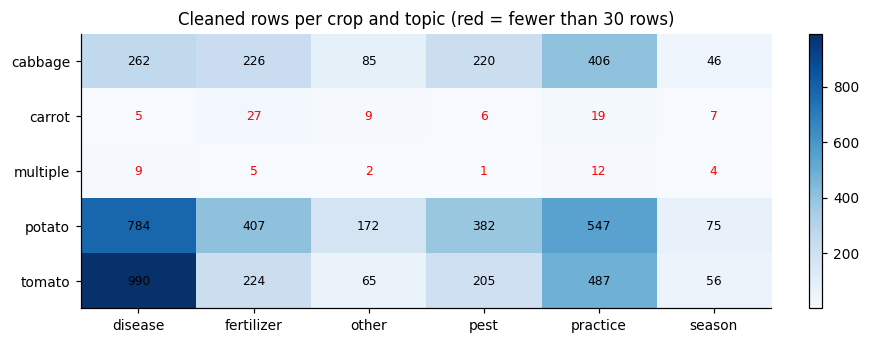

smallest crop-topic cells: {('multiple', 'pest'): 1, ('multiple', 'other'): 2, ('multiple', 'season'): 4, ('carrot', 'disease'): 5, ('multiple', 'fertilizer'): 5}


In [46]:
if RUN_ADVISORY:
    ct = pd.crosstab(w.crop, w.topic)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    im = ax.imshow(ct.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns); ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, int(ct.values[i, j]), ha="center", va="center", fontsize=8, color="red" if ct.values[i, j] < 30 else "black")
    ax.set_title("Cleaned rows per crop and topic (red = fewer than 30 rows)"); plt.colorbar(im, ax=ax, fraction=0.03)
    plt.tight_layout(); plt.show()
    print("smallest crop-topic cells:", ct.stack().sort_values().head(5).to_dict())


**Observation 1.** Read the red cells: crop-topic combinations with fewer than 30 rows. A pattern common in public Q&A sets is that *disease* and *pest* are well covered for tomato and potato while *season* and *fertilizer* are thin for the other crops; check whether yours matches. *Your numbers:* ____

**Implication.** The chatbot will be most reliable where the table is dark and least reliable where it is red, so the accuracy must be reported **by crop and topic**, not as one figure. The red cells are the shopping list for the scraper in section 2.1.

### Observation 2: Answer length differs sharply between sources

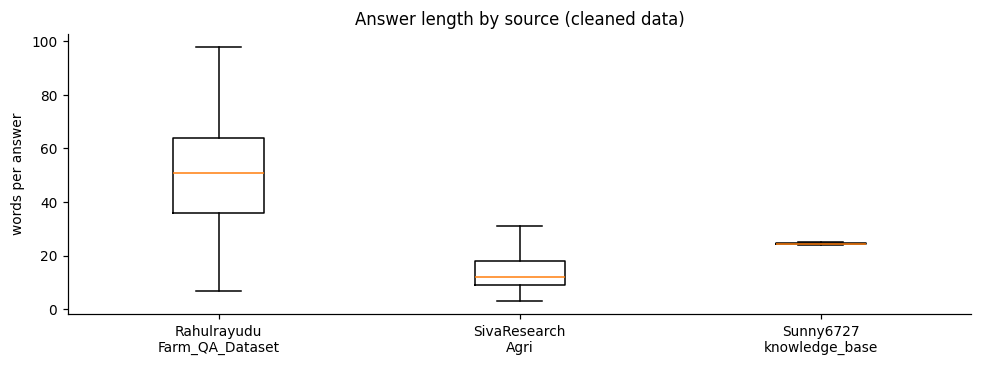

In [47]:
if RUN_ADVISORY:
    w["src"] = w.source.str.split(":").str[0]
    order = sorted(w.src.unique())
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.boxplot([w.loc[w.src == s, "answer_words"] for s in order], labels=[s.replace("/", "\n") for s in order], showfliers=False)
    ax.set_ylabel("words per answer"); ax.set_title("Answer length by source (cleaned data)")
    plt.tight_layout(); plt.show()
    w.groupby("src")["answer_words"].describe()[["count", "25%", "50%", "75%", "max"]].round(0)


**Observation 2.** In the call-centre rows seen so far, answers are mostly one short line, while structured, knowledge-base and scraped answers tend to be a sentence or a paragraph. Compare the medians in the table. *Your numbers:* ____

**Implication.** A model fine-tuned on this mix will switch between a one-line reply and a paragraph depending on how the question is phrased. If you want consistent answers, either train on one length band (for example 15 to 150 words) or add a style instruction to the system prompt. The very short answers are the ones most likely to be incomplete advice.

### Observation 3: One source dominates each crop

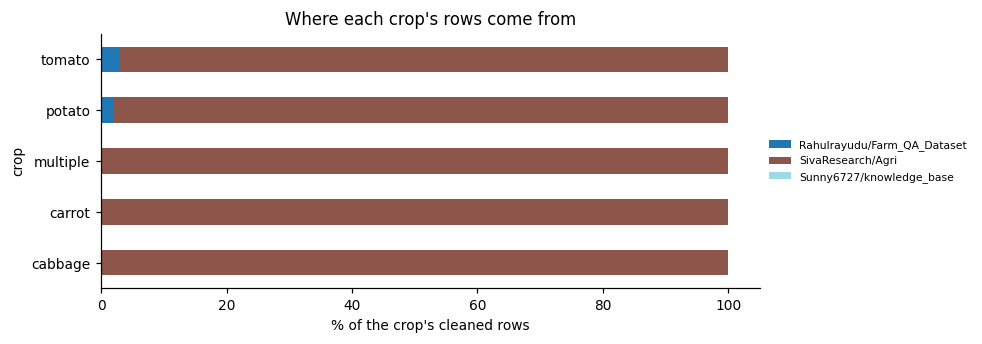

largest source share per crop (%): {'cabbage': 100.0, 'carrot': 100.0, 'multiple': 100.0, 'potato': 98.0, 'tomato': 97.0}


In [48]:
if RUN_ADVISORY:
    share = pd.crosstab(w.crop, w.src, normalize="index") * 100
    ax = share.plot.barh(stacked=True, figsize=(9, 3.2), colormap="tab20")
    ax.set_xlabel("% of the crop's cleaned rows"); ax.set_title("Where each crop's rows come from")
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    plt.tight_layout(); plt.show()
    print("largest source share per crop (%):", share.max(axis=1).round(0).to_dict())


**Observation 3.** If one source supplies more than about 70% of a crop's rows, the model for that crop is effectively a copy of that source, with its wording, its region and its errors. *Your numbers:* ____

**Implication.** Prefer a balance across sources for the final training set (cap the largest source per crop), and report accuracy per source in the test set. A crop that depends on a single source should be treated as a pilot, not a finished feature.

### Observation 4: Which important Kenyan conditions are covered at all?

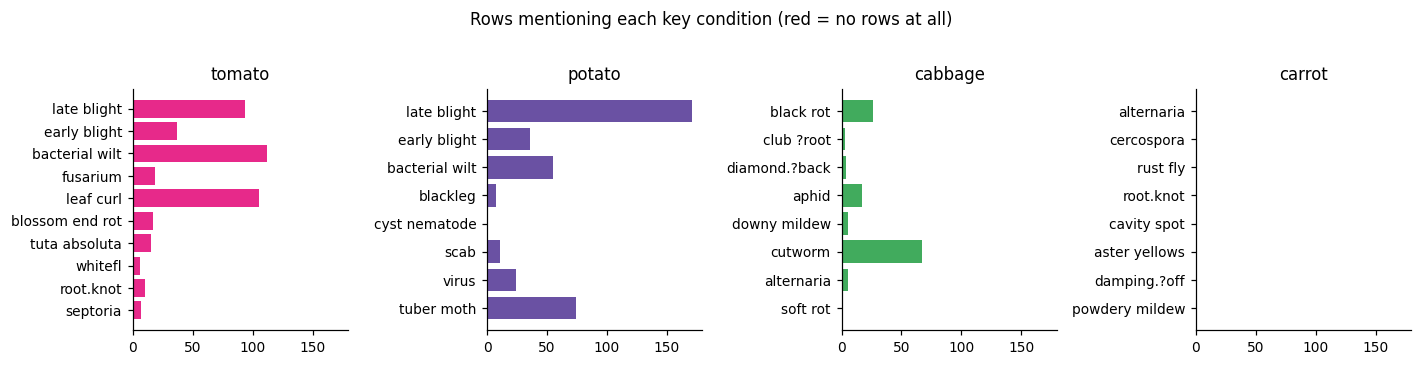

conditions with NO rows: {'cabbage': ['soft rot'], 'carrot': ['alternaria', 'cercospora', 'rust fly', 'root.knot', 'cavity spot', 'aster yellows', 'powdery mildew'], 'potato': ['cyst nematode']}


In [49]:
if RUN_ADVISORY:
    KEY_CONDITIONS = {
        "tomato":  ["late blight", "early blight", "bacterial wilt", "fusarium", "leaf curl", "blossom end rot", "tuta absoluta|leaf ?miner", "whitefl", "root.knot|nematode", "septoria"],
        "potato":  ["late blight", "early blight", "bacterial wilt|brown rot", "blackleg|soft rot", "cyst nematode|\\bpcn\\b", "scab", "virus|leaf roll", "tuber moth|aphid"],
        "cabbage": ["black rot", "club ?root", "diamond.?back|\\bdbm\\b", "aphid", "downy mildew", "cutworm|caterpillar|worm", "alternaria|leaf spot", "soft rot"],
        "carrot":  ["alternaria|leaf blight", "cercospora", "rust fly", "root.knot|nematode", "cavity spot|pythium", "aster yellows|yellows", "damping.?off", "powdery mildew"],
    }
    txt = (w.question + " " + w.answer).str.lower()
    rows = []
    for c, conds in KEY_CONDITIONS.items():
        mask_crop = w.crops_found.str.contains(c)
        for cond in conds:
            rows.append({"crop": c, "condition": cond.split("|")[0], "rows": int((mask_crop & txt.str.contains(cond, regex=True)).sum())})
    condcov = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True)
    for ax, (c, g) in zip(axes, condcov.groupby("crop", sort=False)):
        ax.barh(g.condition[::-1], g.rows[::-1], color=np.where(g.rows[::-1] == 0, "#d73027", palette[c])); ax.set_title(c)
    plt.suptitle("Rows mentioning each key condition (red = no rows at all)", y=1.02); plt.tight_layout(); plt.show()
    print("conditions with NO rows:", condcov[condcov.rows == 0].groupby("crop")["condition"].apply(list).to_dict())


**Observation 4.** The list in `KEY_CONDITIONS` is a checklist of the main diseases and pests of the four crops in East Africa (edit it with your agronomist). A condition with zero rows is a **blind spot**: the chatbot will either invent an answer or confuse it with a similar condition. *Your numbers:* ____

**Implication.** This is the most useful table for the project goal of *distinguishing* symptoms and diseases. Look in particular at diseases with similar symptoms (early blight against late blight; bacterial against fungal wilt) and check that each has its own rows, with the symptoms described. If a pair has symptom text for only one of them, the model cannot learn the difference.

### Observation 5: Doses and quantities are common, and they are the risky part

In [50]:
if RUN_ADVISORY:
    q_by_topic = w.groupby("topic").agg(rows=("question", "size"), with_quantity=("has_quantity", "mean"), flagged_for_review=("needs_review", "sum")).round(2)
    display(q_by_topic)
    units = Counter(re.sub(r"^[\d.,\s]+", "", m.group(0)).lower() for a in w.answer for m in QUANTITY_RE.finditer(a))
    print("units found in answers:", dict(units.most_common(10)))
    print("answers with a dose AND a local term or unit:", int((w.has_quantity & w.region_specific).sum()))


,rows,with_quantity,flagged_for_review
topic,,,
disease,2050,0.91,1869
fertilizer,889,0.87,770
other,333,0.46,0
pest,814,0.93,754
practice,1471,0.60,0
season,188,0.32,0


units found in answers: {'kg': 1899, 'ml': 1563, 'gm': 1409, 'gram': 828, 'g': 454, '%': 314, 'litre': 168, 'litres': 82, 'liter': 82, 'grams': 30}
answers with a dose AND a local term or unit: 718


**Observation 5.** Fertilizer and pesticide answers can carry numbers in many different units (kg per acre, grams per litre, ml per pump, bags per bigha), and the same product can come with different doses from different sources. Check the unit list printed above. *Your numbers:* ____

**Implication.** A model learns the *format* of a dose, not the agronomy behind it, and a confident wrong rate can burn a crop. The `needs_review` rows must be checked by an agronomist, and the system prompt should tell the model to give a range from the product label or to refer to an extension officer. Do not rely on a single "dose" from the data without a Kenyan source.

### Observation 6: Many answers are reused for several questions

answers used for more than one question: 337 of 5,073 distinct answers (17.6% of rows)


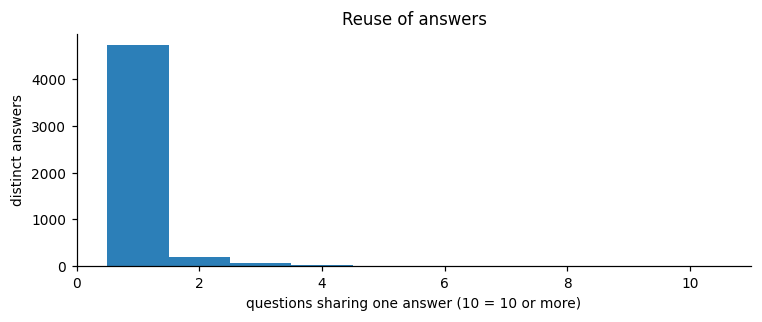

In [51]:
if RUN_ADVISORY:
    reuse = w.groupby("answer").agg(questions=("question", "size"), crop=("crop", "first")).sort_values("questions", ascending=False)
    print(f"answers used for more than one question: {int((reuse.questions > 1).sum())} of {len(reuse):,} distinct answers "
          f"({w.answer.duplicated(keep=False).mean() * 100:.1f}% of rows)")
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(reuse.questions.clip(upper=10), bins=np.arange(0.5, 11.5, 1), color="#2c7fb8")
    ax.set_xlabel("questions sharing one answer (10 = 10 or more)"); ax.set_ylabel("distinct answers"); ax.set_title("Reuse of answers")
    plt.tight_layout(); plt.show()
    reuse.head(5)


**Observation 6.** Answers repeated for many different questions are either generic ("apply recommended fertilizer"), or the same fact paraphrased several times. *Your numbers:* ____

**Implication.** Heavily reused answers make the model more likely to produce the same sentence regardless of the question, and they are the reason the train/test split in section 7 is made by answer group. Consider capping the number of rows per answer (for example, 3) in the final training set.

## 9. Critical reflection: assumptions, limitations and what was deliberately not done

| Decision | Why | What could go wrong | What would improve it |
|---|---|---|---|
| Crop taken from the source label, otherwise from the **question** only | Answers mention other crops in passing | Questions that never name the crop are lost | Add conversation context (the crop is usually named earlier in a real chat) |
| Keyword rules for topic | Transparent and checkable | Some rows get a debatable primary topic | A small labelled sample plus a classifier |
| Removing no-information and very short answers | A model copies what it is trained on | A genuine very short answer is lost | Keep short answers that contain a dose or a product name |
| Keeping the **longest** answer for a repeated question | Needs no judgement about quality | The longest is not always the best or the most correct | Rank sources by trust and keep the best-ranked answer |
| Typo table | Fixes known errors without touching product names | Misses new typos in new sources | Review the most frequent rare words after each new source |
| Region and unit rows **flagged, not converted** | A *bigha* varies between states, so a conversion would be a guess | Indian practice can pass the flag unnoticed | Prefer Kenyan sources; add the region to each source |
| Dose answers flagged `needs_review`, not removed | The advice is useful, the number is the risk | Nobody reviews them | An agronomist signs off before release |
| Group-based hash split | Stops paraphrases leaking into the test set | Not stratified, thin cells may have no test rows | Hand-pick test questions for thin crop-topic cells |
| LLM-generated source switched off | It contains factual errors | Less data | Include it only after manual review |
| No paraphrase generation, no copying between crops | Would invent coverage that is not there | Thin cells stay thin | Scrape or collect more Kenyan sources |
| Scraping only with robots.txt, a delay, and a source label | Respect for the site and a credit trail | Some sites cannot be used | Ask KALRO or the Ministry for a licensed copy |

**Limits that cleaning cannot remove.** (1) Public sets are mostly Indian, so Kenyan seasons, varieties and products are under-represented unless scraped sources are added. (2) The data contains **no symptom descriptions in farmers' own words** for many conditions, so the chatbot can answer "what is the treatment for late blight" better than "my leaves have brown patches with a pale ring, what is it". (3) Fertilizer and chemical advice has to be reviewed by a person. (4) Fine-tuning teaches style and facts, but it does not guarantee that the facts are correct: for a safety-sensitive advisory tool, retrieval over the cleaned rows (so every answer can be traced back to a source) is a stronger design than fine-tuning alone. (5) Text only: no images, so the model cannot look at a leaf.

**Reproducibility.** The notebook rebuilds the dataset from the raw sources, checks its own integrity (section 4), reconciles with the earlier export, and all parameters (crop patterns, topic keywords, minimum lengths, typo table, test share) are set in one place (section 1), so that new sources can be added and the whole process re-run.

## 2.1 Train the advisory retrieval engine
TF-IDF assigns higher weights to informative terms in questions. The vectorizer learns its vocabulary and term weights using only eligible training questions. Cosine similarity measures how close a farmer's question is to known questions. We restrict matches to the selected crop and exclude answers flagged for review. The model abstains when similarity is too low.

The fixed similarity threshold is a prototype setting, not a calibrated probability. The existing answer-group test split is retained; topic agreement measures retrieval relevance, not clinical/agronomic correctness.

In [52]:
if RUN_ADVISORY:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    from sklearn.metrics import classification_report
    import joblib

    eligible = f[f.train_ok & ~f.needs_review.astype(bool) & f.crop.isin(CROPS)].copy()
    ad_train = eligible[eligible.split == "train"].reset_index(drop=True)
    ad_test = eligible[eligible.split == "test"].reset_index(drop=True)
    assert len(ad_train) > 0, "No eligible training rows"
    assert not set(ad_train.group) & set(ad_test.group)
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    ad_vectors = vectorizer.fit_transform(ad_train.question)
    SIM_THRESHOLD = 0.15

    def advise(crop, question, threshold=SIM_THRESHOLD):
        crop = str(crop).strip().lower()
        question = str(question).strip()
        if not question:
            raise ValueError("Enter a question.")
        ids = np.flatnonzero(ad_train.crop.to_numpy() == crop)
        if not len(ids):
            return {"status": "unsupported crop", "answer": "Consult an extension officer."}
        scores = cosine_similarity(vectorizer.transform([question]), ad_vectors[ids]).ravel()
        j = int(np.argmax(scores))
        row = ad_train.iloc[ids[j]]
        score = float(scores[j])
        result = {"similarity": round(score, 3), "matched_question": row.question,
                  "topic": row.topic, "source": row.source}
        if score < threshold:
            return dict(result, status="low similarity", answer="No reliable match. Consult an extension officer.")
        return dict(result, status="retrieved", answer=row.answer,
                    caution="General reference only; verify local conditions with an extension officer.")

    joblib.dump({"vectorizer": vectorizer, "vectors": ad_vectors, "records": ad_train,
                 "threshold": SIM_THRESHOLD}, OUT_DIR / "advisory_model.joblib")
    print("Training questions:", len(ad_train), "| Test questions:", len(ad_test))


Training questions: 1889 | Test questions: 203


## 2.2 Test and validate the advisory engine
For each unseen question, retrieve an answer from training data. Report coverage (the proportion answered), topic agreement for answered questions, and a simple most-common-topic baseline on the same answered subset. The test cannot establish whether an answer is agronomically correct; expert review is required.

In [53]:
if RUN_ADVISORY:
    ad_rows = []
    for r in ad_test.itertuples(index=False):
        result = advise(r.crop, r.question)
        ad_rows.append({"crop": r.crop, "question": r.question, "actual_topic": r.topic,
                        "predicted_topic": result.get("topic"), "status": result["status"],
                        "similarity": result.get("similarity", 0), "answer": result["answer"]})
    ad_eval = pd.DataFrame(ad_rows)
    if len(ad_eval):
        answered = ad_eval[ad_eval.status == "retrieved"].copy()
        print(f"Coverage: {len(answered)/len(ad_eval):.1%} ({len(answered)}/{len(ad_eval)})")
        if len(answered):
            majority = ad_train.groupby("crop").topic.agg(lambda s: s.mode().iloc[0])
            print("Topic agreement:", round((answered.actual_topic == answered.predicted_topic).mean()*100, 2), "%")
            print("Majority-topic baseline:", round((answered.actual_topic == answered.crop.map(majority)).mean()*100, 2), "%")
            print(classification_report(answered.actual_topic, answered.predicted_topic, zero_division=0))
        display(ad_eval.head(10))
    else:
        print("No eligible held-out examples; collect additional data before claiming validation.")


Coverage: 99.5% (202/203)
Topic agreement: 77.23 %
Majority-topic baseline: 68.81 %
              precision    recall  f1-score   support

     disease       0.83      0.88      0.86        17
  fertilizer       0.25      0.20      0.22         5
       other       0.32      0.53      0.40        17
        pest       1.00      0.50      0.67         6
    practice       0.88      0.86      0.87       139
      season       0.67      0.44      0.53        18

    accuracy                           0.77       202
   macro avg       0.66      0.57      0.59       202
weighted avg       0.80      0.77      0.78       202



,crop,question,actual_topic,predicted_topic,status,similarity,answer
0,cabbage,asking about to controll of black rot in cabbage.,disease,practice,retrieved,0.638,suggestedhim to apply malathion 1.5ml/liter of water.
1,cabbage,asking about package & practices of cabbage,fertilizer,fertilizer,retrieved,0.825,"suggested in details about variety,sowing time,fertilizers dose,manures,seed treatment,seed rate of cabbag..."
2,cabbage,asking about dampping of cabbage,other,other,retrieved,0.764,advised to spray bevisting 2 gm/lit.
3,cabbage,"asking about the varities of cabbage , radish ,cauliflower , knolkhol",other,other,retrieved,0.707,"suggested him pride of india,golden acre"
4,cabbage,asking about the varities of cabbages,other,other,retrieved,0.668,"suggested him pride of india,golden acre"
5,cabbage,asking plant protection in cabbage,other,other,retrieved,0.712,spray imidacloprid @ 1ml/3l at 1 week interval.
6,cabbage,query regarding varities of cabbage,other,other,retrieved,0.639,"recommended to cultivate pride of india , golden acor and for knol khol - white viana"
7,cabbage,pest attack in cabbage,pest,pest,retrieved,0.816,suggested him to apply malathion water
8,cabbage,asking about cabbage butterfly problem.,practice,practice,retrieved,0.768,advised to spray malathion 50 ec @ 2ml/ litre water
9,cabbage,asking about cultivation practices of early cabbage,practice,fertilizer,retrieved,0.602,"suggested in details about variety,sowing time,fertilizers dose,manures,seed treatment,seed rate of cabbag..."


## 2.3 Live demonstration — crop advisory
Act as a farmer: choose a crop and enter a question. The engine returns the closest matching advice or abstains. Similarity is not a probability of correctness.

The demonstration uses a more conservative similarity threshold (0.50, illustrative rather than tuned), and withholds dosage and region-specific advice for manual review. The evaluation above measures the underlying retrieval engine at its original threshold; it is not a validation of this additional display policy. Even a high similarity score does not guarantee a correct answer.

In [54]:
if RUN_ADVISORY:
    def farmer_advice(crop, question):
        # Conservative display policy; not a validated diagnostic system.
        result = advise(crop, question, threshold=0.50)
        if result["status"] != "retrieved":
            return {"status": result["status"], "answer": "No reliable match. Consult a local extension officer."}
        answer = result["answer"]
        if QUANTITY_RE.search(answer) or REGION_RE.search(answer) or re.search(r"\b(?:dose|dosage|spray|pesticide|fungicide|insecticide)\b", answer, re.I):
            return {"status": "review required", "similarity": result["similarity"],
                    "answer": "This match may involve treatment advice. Consult a local extension officer."}
        return {"status": "reference only", "similarity": result["similarity"], "answer": answer,
                "caution": "Not a diagnosis; verify advice locally."}

    ADVISORY_CROP = "tomato"
    FARMER_QUESTION = "What are common diseases affecting tomato plants?"
    display(farmer_advice(ADVISORY_CROP, FARMER_QUESTION))
    display(farmer_advice("tomato", "Why are the leaves of my tomato plant turning yellow?"))
    display(farmer_advice("tomato", "quantum spaceship navigation"))


{'status': 'reference only',
 'similarity': 0.603,
 'answer': 'Common tomato diseases include early blight, late blight, powdery mildew, and bacterial spot. Integrated disease management (IDM) practices involve cultural, biological, and chemical control methods to manage diseases effectively. Cultural practices include crop rotation, sanitation, and planting disease-resistant varieties. Biological control methods involve using antagonistic microorganisms or beneficial insects to suppress disease pathogens. Chemical control methods include the use of fungicides and bactericides following recommended guidelines.',
 'caution': 'Not a diagnosis; verify advice locally.'}

{'status': 'low similarity',
 'answer': 'No reliable match. Consult a local extension officer.'}

{'status': 'low similarity',
 'answer': 'No reliable match. Consult a local extension officer.'}

# 4. End-user demonstration and handover
- Select a crop and market, enter a buyer offer, and optionally provide a retail price. Explain the quantile model, its predicted range and the assumed fairness benchmark.
- Request nearby markets. The deployed engine ranks expected wholesale price minus transport cost and excludes very stale prices.
- Select a crop and ask a farming question. Explain TF-IDF similarity and the abstention response.

**Validation status:** price training, historical evaluation and app inference were executed successfully on the provided ZIP data; the original price API also passed 10 automated tests. Advisory training and held-out retrieval evaluation use the supplied cleaned Q&A data; topic agreement is a proxy, not agronomic correctness. The supplied Android/API implementation covers price functionality; advisory mobile integration is not demonstrated here. Neither historical wholesale estimates nor text retrieval establish actual farm-gate fairness or disease diagnosis accuracy.

**Observed advisory limitations:** held-out topic agreement was 77.23% (not answer accuracy), and several natural symptom queries produced weak or incorrect matches. The conservative display policy is a demonstration safeguard only; expert review and mobile integration are still required.